<a href="https://colab.research.google.com/github/Maitebeleen/proyecto-opti/blob/main/Proyecto_Optimizaci%C3%B3n_Arredondo_Bascu%C3%B1%C3%A1n_Eyheramendy_Moreno_Rocha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto de Optimización**

**Optimización, Sección 2**

**Alumnos:**
*   Francisco Arredondo
*   Francisca Bascuñán
*   Sofía Eyheramendy
*   Maite Moreno
*   Fernanda Rocha

**Profesora:** \
Viviana Barile

**Fecha:** \
15 de Noviembre del 2026




# Códigos

***Códigos que se tienen que correr para que funcione el colab***

*Declaración de IA: Para la realización de este código se utilizó ChatGPT.

In [ ]:
!pip install -q gurobipy
from google.colab import drive
drive.mount('/content/drive')
import os
os.environ['GRB_LICENSE_FILE'] = '/content/drive/MyDrive/gurobi.lic'
import gurobipy as gp
gp.Model()

Mounted at /content/drive
Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2883714
Academic license 2883714 - for non-commercial use only - registered to fr___@alumnos.uai.cl


<gurobi.Model Continuous instance Unnamed: 0 constrs, 0 vars, Parameter changes: LicenseID=2883714>

In [ ]:
# =============================================================================
# DATOS DEL PROYECTO 2026-2: FIESTA DE VERANO DE VILLA PEUMAYÉN
# ING200: Optimización
#
# Este archivo contiene los datos del proyecto y dos funciones de apoyo:
#   - demanda(artistas): estima el público que convoca un conjunto de artistas.
#   - mostrar_parrilla(parrilla): muestra una parrilla y su público por noche.
# Puede copiar todo su contenido directamente en su script.
#
# Los montos están en millones de pesos (MM$).
# =============================================================================

# -----------------------------------------------------------------------------
# NOCHES DEL FESTIVAL
# FACTOR_NOCHE[n]: fracción de la demanda que asiste la noche n.
# -----------------------------------------------------------------------------
NOCHES = ['Viernes', 'Sábado', 'Domingo']
FACTOR_NOCHE = {'Viernes': 0.90, 'Sábado': 1.00, 'Domingo': 0.85}

# -----------------------------------------------------------------------------
# RECINTOS
# recinto: capacidad (personas) y costo de arriendo por noche (MM$).
# Todos los recintos están disponibles las tres noches.
# -----------------------------------------------------------------------------
RECINTOS = {
    'Plaza de Armas':     {'capacidad': 12000, 'costo': 30},
    'Medialuna':          {'capacidad': 7500,  'costo': 18},
    'Gimnasio Municipal': {'capacidad': 4200,  'costo': 8},
}

# -----------------------------------------------------------------------------
# ARTISTAS
# nombre: género, nivel ('G' grande, 'M' mediano, 'P' pequeño),
#         popularidad (índice individual), costo (MM$) y noches disponibles.
# -----------------------------------------------------------------------------
ARTISTAS = {
    'La Sonora Copihue':           {'genero': 'Cumbia',  'nivel': 'G', 'popularidad': 1.08, 'costo': 52, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Los Volcanes':                {'genero': 'Rock',    'nivel': 'G', 'popularidad': 0.97, 'costo': 40, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Camila Arrebol':              {'genero': 'Pop',     'nivel': 'G', 'popularidad': 1.03, 'costo': 48, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Kevo Flow':                   {'genero': 'Urbano',  'nivel': 'G', 'popularidad': 1.12, 'costo': 58, 'noches': ['Viernes', 'Sábado']},
    'Los Cumbiancheros del Ñuble': {'genero': 'Cumbia',  'nivel': 'M', 'popularidad': 0.94, 'costo': 18, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Grupo Tierra Sur':            {'genero': 'Folclor', 'nivel': 'M', 'popularidad': 1.06, 'costo': 15, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'La Nena Real':                {'genero': 'Urbano',  'nivel': 'M', 'popularidad': 1.01, 'costo': 22, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Las Hermanas Quintral':       {'genero': 'Pop',     'nivel': 'M', 'popularidad': 0.92, 'costo': 17, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Ruta Cinco':                  {'genero': 'Rock',    'nivel': 'M', 'popularidad': 1.04, 'costo': 16, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Banda Fogata':                {'genero': 'Cumbia',  'nivel': 'P', 'popularidad': 1.11, 'costo': 7,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Conjunto Raíces del Valle':   {'genero': 'Folclor', 'nivel': 'P', 'popularidad': 0.98, 'costo': 5,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Las Cantoras de Peumayén':    {'genero': 'Folclor', 'nivel': 'P', 'popularidad': 0.89, 'costo': 4,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Niebla Austral':              {'genero': 'Rock',    'nivel': 'P', 'popularidad': 0.95, 'costo': 6,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Tomás del Lago':              {'genero': 'Pop',     'nivel': 'P', 'popularidad': 1.09, 'costo': 8,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Yisus Beat':                  {'genero': 'Urbano',  'nivel': 'P', 'popularidad': 0.91, 'costo': 6,  'noches': ['Viernes', 'Sábado', 'Domingo']},
}

# -----------------------------------------------------------------------------
# REGLAS ENTRE ARTISTAS
# TELONEROS: si se contrata al primero, el segundo debe presentarse la misma noche.
# EXCLUSIONES: no pueden ser contratados ambos.
# -----------------------------------------------------------------------------
TELONEROS = [('La Sonora Copihue', 'Banda Fogata')]
EXCLUSIONES = [('La Nena Real', 'Yisus Beat')]

# -----------------------------------------------------------------------------
# PARÁMETROS GENERALES
# -----------------------------------------------------------------------------
PRESUPUESTO = 250              # MM$: artistas + arriendo de recintos + plan de seguridad
UMBRAL_SEGURIDAD = 20000       # personas: si el público total del festival lo supera, se exige el plan
COSTO_SEGURIDAD = 25           # MM$

# -----------------------------------------------------------------------------
# PARÁMETROS DE LA FUNCIÓN DE DEMANDA (usados por la función demanda)
# -----------------------------------------------------------------------------
BASE_NIVEL = {'G': 4200, 'M': 1900, 'P': 750}
FACTOR_GENERO = {'Cumbia': 1.20, 'Urbano': 1.10, 'Pop': 1.00, 'Rock': 0.95, 'Folclor': 0.65}
ARRASTRE = 0.20                # aumento de la base de artistas M y P si en la noche hay un artista G
MISMO_GENERO = -0.15           # por cada par de artistas del mismo género
DOS_GRANDES = -0.10            # por cada par de artistas grandes
AFINIDAD = {('Cumbia', 'Urbano'): 0.06, ('Pop', 'Rock'): 0.05, ('Pop', 'Urbano'): 0.03}


def demanda(artistas):
    """Demanda esperada (personas) de un conjunto de artistas que se presentan la misma noche.

    No considera la noche ni el recinto: el público esperado de la noche n en el recinto r es
        min(FACTOR_NOCHE[n] * demanda(artistas), capacidad del recinto r),
    redondeado al entero más cercano.

    Ejemplo: demanda(['Kevo Flow', 'Ruta Cinco', 'Banda Fogata'])
    También acepta conjuntos de uno o dos artistas (útil, por ejemplo, para analizar cancelaciones).
    """
    artistas = list(artistas)
    hay_grande = any(ARTISTAS[a]['nivel'] == 'G' for a in artistas)
    base = 0.0
    for a in artistas:
        datos = ARTISTAS[a]
        b = BASE_NIVEL[datos['nivel']] * FACTOR_GENERO[datos['genero']] * datos['popularidad']
        if hay_grande and datos['nivel'] != 'G':
            b *= 1 + ARRASTRE
        base += b
    interaccion = 0.0
    for i in range(len(artistas)):
        for j in range(i + 1, len(artistas)):
            a1, a2 = ARTISTAS[artistas[i]], ARTISTAS[artistas[j]]
            if a1['genero'] == a2['genero']:
                interaccion += MISMO_GENERO
            interaccion += AFINIDAD.get((a1['genero'], a2['genero']), AFINIDAD.get((a2['genero'], a1['genero']), 0))
            if a1['nivel'] == 'G' and a2['nivel'] == 'G':
                interaccion += DOS_GRANDES
    return base * (1 + interaccion)


def mostrar_parrilla(parrilla, titulo='Parrilla del festival'):
    """Muestra una parrilla con su público y su costo por noche.

    parrilla: lista de tuplas (noche, recinto, [artista1, artista2, artista3]), por ejemplo
        [('Viernes', 'Medialuna', ['Kevo Flow', 'Ruta Cinco', 'Banda Fogata']), ...]
    El costo mostrado incluye artistas y recinto, pero no el plan de seguridad.
    """
    import matplotlib.pyplot as plt
    orden = {n: i for i, n in enumerate(NOCHES)}
    parrilla = sorted(parrilla, key=lambda t: orden[t[0]])
    print(f'{titulo}\n' + '-' * 100)
    total_pub, total_costo, publicos = 0, 0, []
    for noche, recinto, artistas in parrilla:
        pub = round(min(FACTOR_NOCHE[noche] * demanda(artistas), RECINTOS[recinto]['capacidad']))
        costo = sum(ARTISTAS[a]['costo'] for a in artistas) + RECINTOS[recinto]['costo']
        total_pub += pub; total_costo += costo; publicos.append(pub)
        nombres = ', '.join(f"{a} ({ARTISTAS[a]['nivel']})" for a in artistas)
        print(f'{noche:8s} | {recinto:18s} | {pub:6,d} personas | {costo:4d} MM$ | {nombres}')
    print('-' * 100 + f'\nTotal: {total_pub:,} personas | {total_costo} MM$ (sin plan de seguridad)')
    plt.figure(figsize=(7, 3.5))
    barras = plt.bar([p[0] for p in parrilla], publicos, color=['#1565c0', '#c62828', '#2e7d32'][:len(parrilla)])
    for b, (noche, recinto, _) in zip(barras, parrilla):
        plt.text(b.get_x() + b.get_width() / 2, b.get_height(), recinto, ha='center', va='bottom', fontsize=9)
    plt.ylabel('Público esperado'); plt.title(titulo); plt.tight_layout(); plt.show()

# *Item a)*

***Pregunta:*** \
Formule un modelo de programación lineal entera que permita a la municipalidad decidir
qué tres artistas se presentan cada noche y en qué recinto, de modo de maximizar
el público total esperado respetando todas las condiciones descritas. Defina claramente
**conjuntos, parámetros y variables de decisión, y explique el significado de cada restricción**. \
Explique cómo incorpora la función de *demanda en su modelo* y por qué su *modelo es
lineal*, a pesar de que la demanda de una noche no es la suma de las demandas de cada
artista.

***Respuesta:***

***Formulación modelo:***

Para definir los **parámetros**, tenemos que considerar que, estos son datos que nos da el mismo enunciado, por ende no podemos decidir sobre ellos.

<br>

* $CostoA_a$: Costo en millones de pesos [MM\$] de contratar el artista $a$.

<br>

* $CostoR_r$: Costo en millones de pesos [MM\$] de arriendo del recinto $r$ por una noche.

<br>

* $$Disp_{a,n} = \begin{cases}
1 & \text{si el artista $a$ puede presentarse en la noche $n$ (según su disponibilidad)} \\
0 & \text{en otro caso}
\end{cases}$$

$$Disp_{a,n} \in \{0, 1\}$$

  **Acotación:* La disponibilidad de cada artista se encuentra en el código accediendo a este con la siguiente línea de código:
  \
  *ARTISTAS['NOMBRE ARTISTA']['noches']*.

<br>

* $D(c)$ : Demanda estimada de la combinación de artistas $c$ que se presentan en la misma noche, calculada a partir de la siguiente fórmula:
$$D(c) = \left( \sum_{a \in c} b_a \right) (1 + I).$$\
  con $b_a$: Demanda base del artista $a$, calculada a partir de la multiplicación de la base según su nivel, el factor de su género, su popularidad y un posible efecto arrastre.

  con $I$: Ajuste de interacción entre los artistas de la combinación $c$.

  <br>

* $P_{c,n,r}$ :  Público esperado de la combinación de artistas $c$ en la noche $n$ en el recinto $r$, calculada a partir de la siguiente fórmula (redondeado al entero más cercano): $$min(Ø_n \cdot D(c) \, ,\, K_r )$$

  con $Ø_n$: Factor de asistencia por noche.\
  con $K_r$: Capacidad del recinto.

  <br>

* $Presupuesto$ = 250 [MM\$]

<br>

* $Umbral$ $de$ $seguridad$ = 20 000\
  (si el público total supera este número, la municipalidad debe implementar un plan de seguridad)

  <br>

* $Costo$ $de$ $Seguridad$ = 25 [MM\$]

<br>

* $M$ : Big-M en caso que se requiera activar o desactivar una condición mediante una variable binaria; en este caso el plan de seguridad . \
**Acotación*:  Para el código, posteriormente se utilizará $M= 16 \ 000$, pues el el valor más ajustado según las capacidades posibles de los recintos.




Primeramente, definiremos los **conjuntos** requeridos:

* **$A$**:  Conjunto de todos los artistas candidatos $A= \{a_1,a_2, ... ,a_{15}\}$ = {"La Sonora Copihue", "Los volcanes",..., "Yisus Beat"}.

* **$N$**:  Conjunto de noches del festival $N$= {Viernes, Sábado, Domingo}.\
**Acotación:* Este conjunto para el código, al momento de programar, será la lista $NOCHES$.

* **$R$**:  Conjunto de recintos disponibles $R$= {Plaza de Armas, Medialuna, Gimnasio Municipal}.\
**Acotación:* Este conjunto para el código, al momento de programar, será la lista $RECINTOS$.

* **$C$**:  Conjunto de todas las combinaciones posibles de exactamente tres artistas distintos (para cada noche) pertenencientes a $A$, es decir, $C = \{c \subseteq A : |c| = 3\}$.


Para las **variables de decisión**, se consideran las opciones que permitiran resolver el problema a través del uso de Gurobi.

* $$X_{c,n,r} = \begin{cases}
1 & \text{si se asigna la combinación de artistas $c$ en la noche $n$ al recinto $r$} \\
0 & \text{en otro caso}
\end{cases}$$

$$X_{c,n,r} \in \{0, 1\}$$

<br>

* $$Y_{a} = \begin{cases}
1 & \text{si el artista $a$ es contratado para participar en el festival} \\
0 & \text{en otro caso}
\end{cases}$$

$$Y_{a} \in \{0, 1\}$$

<br>

* $$S = \begin{cases}
1 & \text{si se activa el plan de seguridad} \\
0 & \text{en otro caso}
\end{cases}$$

$$S \in \{0, 1\}$$


Considerando que el objetivo de la municipalidad es maximizar el público total esperado del festival, se definirá de la siguiente forma la *función objetivo* :

**Función objetivo**:

$$ \max \ z = \sum_{n \in N} \sum_{r \in R} \sum_{c \in C} P_{c,n,r} \cdot X_{c,n,r} $$\
La triple sumatoria dentro de la función asegura que se maximizará el público total ($P_{c,n,r}$) entre las tres noches, independientente del recinto o las combinaciones de artistas, pues se suma el público que se presentará en todas las noches ($\sum_{n \in N}$), en todos los recintos ($\sum_{r \in R}$) y se consideran todas las combinaciones posibles de artistas ($\sum_{c \in C}$). Cada suma individual está sujeta a que la combinación específica de artistas *c* se asigne al recinto *r* en la noche $n$ ($ X_{c,n,r}$=1), de lo contrario el valor será cero.

**Restricciones**:

1. Asignación única: Cada noche $n$ debe tener exactamente una combinación de artistas y un recinto asociado.\
$$ \sum_{r \in R} \sum_{c \in C} X_{c,n,r} =1 $$
<center> $\forall n \in N$</center>

 *Explicación de la restricción (1):*\
La restricción establece que, para cada noche del festival, se debe escoger solamente una combinación de tres artistas y un recinto. Para esto, se suman las variables binarias correspondientes a todas las combinaciones y recintos posibles para un día, y se exige que su resultado sea igual a $1$.

2. Un artista $a$ es contratado si alguna combinación de artistas que lo incluye efectivamente es elegida.

$$ Y_a= \sum_{n \in N} \sum_{r \in R} \sum_{c \in C: a \in c} \ X_{c,n,r} $$
<center> $∀ a \in A $<center>

 *Explicación de la restricción (2):*\
 Esta restricción relaciona la variable de contratación $Y_a$ con todas las combinaciones, seleccionadas mediante $X_{c,n,r}$. Así, un artista se considera contratado si es que pertenece a alguna combinación (con una noche y recinto asignado). Además, como $Y_a$ es una variable binaria, ya se limita que un mismo artista sea seleccionado más de una vez durante el festival, cumpliendo con el requisito de que "*cada artista puede presentarse a lo más una vez en el festival* " .

3. Cada artista puede presentarse solo en las noches que está disponible:
$$ \sum_{r \in R} \sum_{c \in C : a \in c} X_{c,n,r} \leq Disp_{a,n} \quad \forall a \in A, \forall n \in N $$


*Explicación de la restricción (3):*\
 Primeramente, se chequea $X_{c,n,r}$ para todos los recintos y todas las combinaciones que contienen el artista $a$, valiendo 1 si es que efectivamente se selecciona esta combinación para la noche $n$ en el recinto $r$. Esto tiene que ser igual o menor a la disponibilidad que tenga el artista, valiendo 1 si el artista $a$ efectivamente está disponible en la noche $n$. Se utiliza un $\leq$ , pues que esté disponible no significa que el artista tenga que presentarse realmente.

4. Si se contrata a  La Sonora Copihue, Banda Fogata debe presentarse la misma noche:

$$ \sum_{r \in R} \sum_{c \in C : a_1 \in c} X_{c,n,r} \leq \sum_{r \in R} \sum_{c \in C : a_{10} \in c} X_{c,n,r}$$
<center> $\forall n \in N$</center>
<center> $a_1$ : La Sonora Copihue</center>
<center> $a_{10}$ : Banda Fogata</center>

<br>

*Explicación de la restricción (4):*\
 Primeramente, se chequea $X_{c,n,r}$ para todos los recintos y todas las combinaciones que contienen al artista $a_1$, es decir, La Sonora Copihue. Luego, se repite el mismo procedimiento para $a_{10}$, es decir, Banda Fogata. Así, se condiciona que si se contrata a La Sonora Copihue, necesariamente se debe contratar a la Banda Fogata, sin embargo  esta es una implicancia en un solo sentido, pues no necesariamente se va a contratar a La Sonora Copihue si es que se contrata la Banda Fogata.



5. La Nena Real y Yisus Beat no aceptan participar en
el mismo festival:\
$$ Y_{a_7}+ Y_{a_{15}} \leq 1 $$
<center> $a_7$ : La Nena Real</center>
<center> $a_{15}$ : Yisus Beat</center>

*Explicación de la restricción (5):*\
 Dado que la Nena Real y Yisus Beat no pueden ser contratados simultáneamente para el festival, independiente de la noche que se presenten, se utiliza la variable $Y_a$ para saber si es que efectivamente fue contratado el artista para participar en el festival. Así, la suma de sus variables tiene que ser menor o igual a $1$ dado que, como posibilidades, puede ser contratado uno de los dos o ninguno.

Si el público total esperado del festival supera las 20 000 personas,
la municipalidad debe implementar un plan de seguridad:

6. Obliga a activar el plan si se supera el umbral de seguridad:

$$ \sum_{n \in N} \sum_{r \in R} \sum_{c \in C} P_{c,n,r}  \cdot \ X_{c,n,r} - 20 \ 000 \leq M \cdot S $$

7. Impide activar el plan cuando no se requiere:

$$ \sum_{n \in N} \sum_{r \in R} \sum_{c \in C} P_{c,n,r}  \cdot \ X_{c,n,r} \geq 20 \ 001 \cdot S $$

<br>

 <center>A partir de la primera restricción, se obliga a que se active el plan de seguridad ($S=1$) cuando el público supera las $20 \ 000$ personas (umbral de seguridad), sin embargo esta restricción no es suficiente pues, permite que $S=1$ aunque el público sea menor o igual a $20 \ 000$, por lo tanto se tendrá una segunda restricción asociada a la seguridad para impedir activar el plan cuando no corresponde. <center>

<br>

*Explicación de la restricción (6 y 7):*\
 Para la primera restricción, se utiliza la sumatoria triple de $P_{c,n,r}  \cdot \ X_{c,n,r}$ para obtener el público total esperado para la totalidad del festival. Así, al realizar la resta con el umbral de seguridad, se determina si este límite es superado. Por ende, a través de $Big\ M$ se puede establecer que cuando $S=0$, el público no puede superar el umbral, en cambio cuando $S=1$ el término "$M \cdot S$" permite superar el límite, obligando así a activar el plan de seguridad. \
Para la segunda restricción, se impone que si se activa el plan de seguridad ($S=1$), el público total (calculado a partir de la triple sumatoria) necesariamente debe ser mayor a $20 \ 000$ personas. Por lo cual, como en la programación lineal entera no se utilizan las desigualdades estrictas, se utiliza $20 \ 001$. Así, se impide activar el plan de seguridad cuando no se supera el umbral establecido.


8. El presupuesto para el evento es de 250 MM\$

$$ \sum_{a \in A} CostoA_a \cdot Y_a + \sum_{n \in N} \sum_{r \in R} CostoR_r \cdot \left( \sum_{c \in C} X_{c,n,r} \right) + 25 \cdot S \leq 250 $$\
considerando que el número $25$ es el Costo de Seguridad en [MM\$] y $250$ el presupuesto total en [MM\$].\
  <br>
 *Explicación de la restricción (8):*\
  Primeramente se analizan todos los costos existentes: con $Y_a$ se pueden visualizar los costos asociados a cada artista que efectivamente se contrató. Asimismo, se chequea primeramente todas las combinaciones que se asociaron a cada noche y recinto ($X_{c,n,r}$), y luego se analiza con el costo de todos los recintos y todas las noches para obtenerlo. Por último esto también se le suma que, en caso que se active el plan de seguridad ($S=1$), se tiene que sumar el costo asociado a este ($25$ [MM\$]). Así la suma de todo esto, tiene que ser menor al presupuesto total ($250$ [MM\$]).



**Explicación de la demanda y el modelo lineal**

Primeramente, la función de demanda $D(c)$, permite precalcular la demanda de cada combinación $c$ de artistas, considerando sus características individuales, el efecto de arrastre y las interacciones entre ellos. Por lo tanto, la demanda conjunta no corresponde simplemente a la suma de sus demandas individuales.

Esta función se incorpora en el parámetro $P_{c,n,r}$, que ajusta cuántas personas asistirán con la respectiva combinación $c$ si se presentan en la noche $n$ y en el recinto $r$ en específico, permitiendo obtener el público esperado para cada alternativa.

Al realizar estos cálculos antes de resolver el modelo como tal, $P_{c,n,r}$ constituye un parámetro constante. Por lo tanto, en la función objetivo, $X_{c,n,r}$ es la única variable de decisión involucrada involucrada y se multiplica por un parámetro constante, manteniendo la linealidad de la expresión.\
De esta manera, el modelo es lineal porque:
* La función objetivo es una suma de variables binarias multiplicadas por constantes.
* Tanto las restricciones como interacciones también se plantean, o se calculan previamente, de forma que no existe ninguna multiplicación entre variables, solamente expresiones lineales.



# Item *b)*

***Pregunta***:
*Implemente y resuelva el modelo de forma computacional. En caso de tener múltiples soluciones óptimas, considere aquella de menor costo total. Una vez resuelto, reporte
respecto a su solución óptima:*

* *Los artistas y el recinto de cada noche, con su público esperado.*
* *El púlico total esperado y el costo total.*
* *Si se requiere el plan de seguridad.*

Para cada parte del código se comentará cada paso realizado.


**Declaración de IA:*
Para la realización de este código se utilizó ChatGPT.


Set parameter MIPGap to value 0
Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Non-default parameters:
MIPGap  0

Academic license 2884705 - for non-commercial use only - registered to fr___@alumnos.uai.cl
Optimize a model with 70 rows, 4111 columns and 42389 nonzeros (Max)
Model fingerprint: 0xc015de44
Model has 4095 linear objective coefficients
Variable types: 0 continuous, 4111 integer (4111 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+04]
  Objective range  [1e+03, 1e+04]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Found heuristic solution: objective 9995.0000000
Presolve removed 48 rows and 2242 columns
Presolve time: 0.14s
Presolved: 22 rows, 1869 columns, 11877 nonzeros
Found heuristic solution: objective 14177.000000
Variable types: 0 continuous, 1869

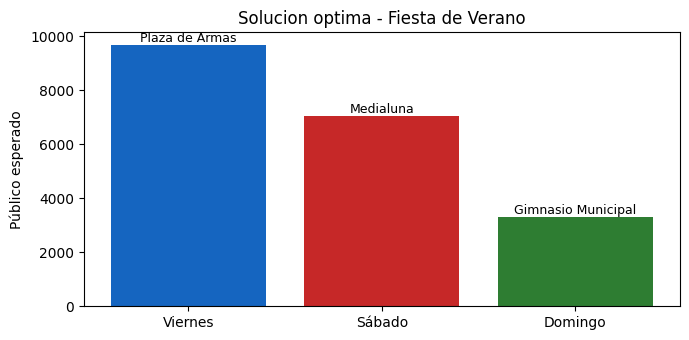

In [ ]:
# -------------------------------------------------------------------------
# LIBRERÍAS
# -------------------------------------------------------------------------

#Se importan librerías requeridas

# De esta librería, se utilizará la función "combinations", lo cual permitirá generar todas las combinaciones posibles de elementos de un conjunto.
# En este caso, como existen 15 artistas disponibles se formaran todas las combinaciones posibles de exactamente 3 artistas.
# Esto corresponde al conjunto c.
# Teóricamente, "combinations" debería generar 455 combinaciones posibles, sin considerar orden ni repeticiones de artistas dentro de cada combinación.
from itertools import combinations



# La librería gurobipy permitirá crear y resolver los modelos de optimización
# Dentro de esta misma librería, la función "GRB" proporciona constantes utilizadas por Gurobi, como "GRB.BINARY", "GRB.MAXIMIZE", "GRB.MINIMIZE".
import gurobipy as gp
from gurobipy import GRB


# -------------------------------------------------------------------------
# 1. Definición de Conjuntos y parametros precalculados
# -------------------------------------------------------------------------

A = list(ARTISTAS)            # Crea la lista con los nombres de los 15 artistas
N = NOCHES
R = list(RECINTOS)            # Lista de los recintos.
C = list(combinations(A, 3))  # Generación de las 455 combinaciones; C[k] es una combinación
K = range(len(C))            # Conjunto auxiliar para la creación para los índices de las combinaciones para Gurobi, así se puede identificar cada combinación con un número.
M = 16000                    # Valor para Big_M, siendo este el máximo de personas en 3 noches (de la totalidad del festival) (36000) - umbral (20000)


# -------------------------------------------------------------------------
# Cálculo del parámetro P_{c,n,r}
# -------------------------------------------------------------------------

P = {
    (k, n, r): round(min(FACTOR_NOCHE[n] * demanda(C[k]),
                         RECINTOS[r]['capacidad']))
    for k in K for n in N for r in R
}
# Esto permitirá entregar el público esperado




# -------------------------------------------------------------------------
# 2. Variables
# -------------------------------------------------------------------------

model = gp.Model('Fiesta_de_Verano') # Creación del modelo de optimización, con nombre "Fiesta de Verano"


#Creación de la variable X_{c,n,r}
X = {(k, n, r): model.addVar(vtype=GRB.BINARY, name=f'X_{k}_{i}_{j}')
     for k in K for i, n in enumerate(N) for j, r in enumerate(R)}

#Para entender el código:
#       mode.addVar() crea la variable de decisión
#       vtype=GRB.BINARY indica que puede tomar solamente los valores 0 o 1
#       name=...: Asigna un nombre a la variable para identificarla


#Creación de la variable Y_a
Y = {a: model.addVar(vtype=GRB.BINARY, name=f'Y_{i+1}')
     for i, a in enumerate(A)}

#Creación de la variable S
S = model.addVar(vtype=GRB.BINARY, name='S')

#Creación del público total en el festival
#   Esta definición corresponde a toda la expresión que está en la función objetivo (La sumatoria triple de P_{c,n,r} * X_{c,n,r})
publico_total = gp.quicksum(P[k, n, r] * X[k, n, r]
                           for k in K for n in N for r in R)

#       gp.quicksum() es la función que permite construir sumatorias.


# Costo de contratación de los artistas, si es que efectivamente fueron contratados.
#       Es la sumatoria de cada uno de los costos de cada artista con la variable Y_a
costo_artistas = gp.quicksum(ARTISTAS[a]['costo'] * Y[a] for a in A)


#Costo de los arriendos de los recintos
#       Es la sumatoria de X_{c,n,r} con el costo del recinto asociado
costo_recintos = gp.quicksum(RECINTOS[r]['costo'] * X[k, n, r]
                             for k in K for n in N for r in R)


# Costo total del festival
#       Se incluyen los dos costos calculados y también el costo de seguridad.
costo_total = costo_artistas + costo_recintos + COSTO_SEGURIDAD * S

# -------------------------------------------------------------------------
# 3. Restricciones
# -------------------------------------------------------------------------

# La función ".addConstr()" permite agregar una restricción al modelo de optimización.


# RESTRICCIÓN 1: Asignación única
#   Cada noche debe tener exactamente una combinación de artistas y un recinto asociado.
for i, n in enumerate(N):
    model.addConstr(gp.quicksum(X[k, n, r] for k in K for r in R) == 1,
                    name=f'una_terna_{i+1}')


# RESTRICCIÓN 2:
#   Un artista es contratado si alguna combinación de artistas que lo incluye efectivamente es elegida
for i, a in enumerate(A):
    model.addConstr(
        Y[a] == gp.quicksum(X[k, n, r]
                            for k in K if a in C[k] for n in N for r in R),
        name=f'contratacion_{i+1}',
    )

# RESTRICCIÓN 3 y 4:
# Un artista puede presentarse solo en las noches que está disponible.
for i, a in enumerate(A):
    for j, n in enumerate(N):
        disponible = int(n in ARTISTAS[a]['noches'])
        model.addConstr(
            gp.quicksum(X[k, n, r] for k in K if a in C[k] for r in R)
            <= disponible,
            name=f'disponibilidad_{i+1}_{j+1}',
        )

# RESTRICCIÓN 5:
# Si se contrata a La Sonora Copihue, Banda Fogata debe presentarse la misma noche.
sonora = 'La Sonora Copihue'
fogata = 'Banda Fogata'
for i, n in enumerate(N):
    model.addConstr(
        gp.quicksum(X[k, n, r] for k in K if sonora in C[k] for r in R)
        <= gp.quicksum(X[k, n, r] for k in K if fogata in C[k] for r in R),
        name=f'telonero_{i+1}',
    )

# RESTRICCIÓN 6
# La Nena Real y Yisus Beat no aceptan participar en el mismo festival
model.addConstr(Y['La Nena Real'] + Y['Yisus Beat'] <= 1,
                name='exclusion')

# RESTRICCIÓN 7 Y 8
# Si el público total esperado del festival supera las 20 000 personas, la municipalidad debe implementar un plan de seguridad.
model.addConstr(publico_total - UMBRAL_SEGURIDAD <= M * S,
                name='seguridad_obligatoria')
model.addConstr(publico_total >= (UMBRAL_SEGURIDAD + 1) * S,
                name='seguridad_solo_si_corresponde')

# RESTRICCIÓN 9
# El presupuesto para el evento es de 250 MM$ (el costo total debe ser menor o igual a este monto)
model.addConstr(costo_total <= PRESUPUESTO, name='presupuesto')


# -------------------------------------------------------------------------
# 4. Generar la primera optimizacion: MAXIMIZAR el público esperado (1*)
# -------------------------------------------------------------------------

# Se establece el parámetro MIPGap en 0, tal y como pide el enunciado
model.Params.MIPGap = 0

# Se establece la función objetivo del modelo, lo que queremos optimizar.
model.setObjective(publico_total, GRB.MAXIMIZE)

# Se ejecuta la optimización
model.optimize()

# Se chequea si es que efectivamente se consiguió demostrar la optimalidad.
if model.Status != GRB.OPTIMAL:
    raise RuntimeError('No se demostro optimalidad en la primera etapa.')


# Se obtiene el valor de la función objetivo de la solución encontrada, en este caso, el valor es el público máximo obtenido.
mejor_publico = round(model.ObjVal)
print(f'\nPublico maximo demostrado: {mejor_publico:,} personas')


# Se encontraron múltiples soluciones que permiten obtener 19 999 personas
# Por lo tanto, se tendrá que realizar una segunda optimización considerando también minimizar el costo, manteniendo el público máximo.


# -------------------------------------------------------------------------
# 5. Segunda optimización: Entre los óptimos, se tendrá que MINIMIZAR el costo
# -------------------------------------------------------------------------

# Se fija una nueva restricción que busca fijar el público máximo encontrado, buscando ahora minimizar el costo.
model.addConstr(publico_total == mejor_publico, name='fijar_publico_optimo')

# Se cambia la función objetivo, ahora buscando minimizar el costo total
model.setObjective(costo_total, GRB.MINIMIZE)

# Se ejecuta la optimización
model.optimize()

# Se chequea si se realizó la optimización
if model.Status != GRB.OPTIMAL:
    raise RuntimeError('No se demostro optimalidad en la segunda etapa.')

# -------------------------------------------------------------------------
# 6. Mostrar la solución y comprobar.
# -------------------------------------------------------------------------
parrilla = []
for n in N:
    for k in K:
        for r in R:
            if X[k, n, r].X > 0.5:
                parrilla.append((n, r, list(C[k])))
                break

print('\nRESULTADOS DE LA PREGUNTA (b)')
for n, r, artistas in parrilla:
    p = round(min(FACTOR_NOCHE[n] * demanda(artistas),
                  RECINTOS[r]['capacidad']))
    arriendo = RECINTOS[r]['costo']
    contrataciones = sum(ARTISTAS[a]['costo'] for a in artistas)
    print(f'{n}: {", ".join(artistas)} | {r} | publico {p:,} '
          f'| costo {arriendo + contrataciones} MM$')

print(f'Publico total: {round(publico_total.getValue()):,} personas')
print(f'Plan de seguridad: {"SI" if S.X > 0.5 else "NO"}')
print(f'Costo artistas: {costo_artistas.getValue():.0f} MM$')
print(f'Costo recintos: {costo_recintos.getValue():.0f} MM$')
print(f'Costo seguridad: {COSTO_SEGURIDAD * round(S.X)} MM$')
print(f'Costo total minimo: {costo_total.getValue():.0f} MM$')

# Visualizacion opcional, proporcionada por el archivo de datos.
mostrar_parrilla(parrilla, titulo='Solucion optima - Fiesta de Verano')

Para resolver el modelo, se realizó un código de programación lineal entera en python usando el *Solver* Gurobi.\
Se utilizó la misma metodología mencionada en el item *a)* en el cual se generan todas las combinaciones posibles y su público esperado, previo a la optimización.\
Así, posterior a aquello se tuvieron que realizar dos optimizaciones para encontrar la solución óptima y su respectivo valor.

Primeramente, se maximizó el público total esperado para el festival, sin embargo existían múltiples combinaciones que permitían obtener esto. Por lo cual, en segundo lugar se realizó otra optimización que, manteniendo el público total óptimo encontrado, minimiza el costo total del festival.

Como resultado de la segunda optmización, se obtuvo la siguiente solución:
* Para la primera noche (Viernes), se presentan Kevo Flow,  Los Cumbiancheros del Ñuble y Las Hermanas Quintral en Plaza de Armas, con un público esperado de $9 \ 657 $ personas.
* Para la segunda noche (Sábado), se presentan Camila Arrebol, Grupo Tierra Sur y  Niebla Austral en el recinto Medialuna, con un público esperado de $ 7 \ 045 $ personas.
* Para la tercera noche (Domigo), se presentan Ruta Cinco, Banda Fogata y Tomás del Lago en el Gimnasio Municipal, con un público esperado de $ 3 \ 297 $ personas.
* Así, el público total esperado es de $19 \ 999 $ personas, con un costo total de $249$ [MM\$] (estando dentro del presupuesto dado).
* Dado que el público no supera las $20 \ 000$ personas, **NO** fue necesario contratar el plan de seguridad.

La solución obtenida es coherente con los factores del modelo y restricciones dados por varias razones. En primer lugar, se puede notar que el público total es de $19 \ 999$ personas, lo cual está justo debajo del umbral de $20 \ 0000$ que activaría el costo del plan de seguridad, aprovechando todo el presupuesto en contratar a los artistas. En segundo lugar, se prioriza presentar los artistas grandes (Kevo Flow y Camila Arrebol) en los días viernes y sábado, que tienen mayor factor de asistencia, y así se asegura activar el efecto arrastre del aumento del $20 \%$ de la demanda de los artistas medianos y pequeños ese día. Luego, la solución óptima asegura que no se repitan artistas del mismo género en la misma noche, para no tener penalización, y se prioriza la afinidad de géneros, que tiene bonificación (viernes: Cumbia y Urbano, sábado: Pop y Rock, domingo: Pop y Rock). Además, la solución prioriza que no hayan dos artistas grandes en la misma noche, para evitar la penalización por este factor, lo que se cumple para todos los días. Finalmente, se prioriza que se utilice el recinto Plaza de Armas para la noche con mayor público, teniendo una capacidad mayor a la que es posible albergar en cualquiera de los otros dos. Luego, se utliza la Medialuna para la segunda noche con más demanda, pues su número está casi al máximo de la capacidad, siendo incompatible con el último recinto. Por último, el Gimnasio Municipal para la noche de menor demanda, asegurando aprovechar al máximo el uso del espacio, pues se sabe que el domingo tendrá tendencia a tener menor demanda. Es por todo esto que se puede interpretar que la solución evita cualquier decisión que podría generar penalización, y dentro de lo posible se busca conseguir las bonificaciones adicionales, siempre priorizando que hayan los mejores artistas y mayor público en los días con mayor factor de asistencia.

# Item *c)*

***Enunciado:***

*El año pasado, la artista principal del sábado canceló su presentación a última hora y el público de esa noche cayó a menos de un tercio de lo esperado. La municipalidad quiere evitar que algo así vuelva a ocurrir.*



## *Pregunta I.*

***Pregunta I.***

*Para cada noche de su solución, determine cuánto público se esperaría si cancela cada uno de los tres artistas y se presentan solo los otros dos. Identifique qué noches dependen más de un solo artista.*


**Declaración de IA* : Para la realización de este código se utilizó Gemini.

In [ ]:
import itertools

# Parrilla base obtenida de la solución óptima del inciso (b)
parrilla_base = [
    ('Viernes', 'Plaza de Armas', ['Kevo Flow', 'Los Cumbiancheros del Ñuble', 'Las Hermanas Quintral']),
    ('Sábado', 'Medialuna', ['Camila Arrebol', 'Grupo Tierra Sur', 'Niebla Austral']),
    ('Domingo', 'Gimnasio Municipal', ['Ruta Cinco', 'Banda Fogata', 'Tomás del Lago'])
]

print("=" * 110)
print(f"{'NOCHE':<10} | {'ARTISTA CANCELADO':<28} | {'ARTISTAS RESTANTES':<45} | {'PÚBLICO ESPERADO'}")
print("-" * 110)

for noche, recinto, artistas_noche in parrilla_base:
    # Calculamos el público original de referencia para esta noche
    demanda_orig = demanda(artistas_noche)
    pub_original = round(min(FACTOR_NOCHE[noche] * demanda_orig, RECINTOS[recinto]['capacidad']))

    # Simulamos la cancelación de cada uno de los 3 artistas uno por uno
    for artista_a_cancelar in artistas_noche:
        # Creamos la combinación de los 2 artistas restantes
        artistas_dos = [a for a in artistas_noche if a != artista_a_cancelar]

        # Recalculamos la demanda y el público con solo 2 artistas
        demanda_dos = demanda(artistas_dos)
        pub_esperado = round(min(FACTOR_NOCHE[noche] * demanda_dos, RECINTOS[recinto]['capacidad']))

        # Diferencia respecto al original
        perdida = pub_original - pub_esperado
        porcentaje = 100 * perdida / pub_original

        restantes_str = ", ".join(artistas_dos)

        print(f"{noche:<10} | {artista_a_cancelar:<28} | {restantes_str:<45} | {pub_esperado:,d} personas ( Pierde: -{perdida:,d} / -{porcentaje:.1f}% )")

    print("-" * 110)

NOCHE      | ARTISTA CANCELADO            | ARTISTAS RESTANTES                            | PÚBLICO ESPERADO
--------------------------------------------------------------------------------------------------------------
Viernes    | Kevo Flow                    | Los Cumbiancheros del Ñuble, Las Hermanas Quintral | 3,502 personas ( Pierde: -6,155 / -63.7% )
Viernes    | Los Cumbiancheros del Ñuble  | Kevo Flow, Las Hermanas Quintral              | 6,741 personas ( Pierde: -2,916 / -30.2% )
Viernes    | Las Hermanas Quintral        | Kevo Flow, Los Cumbiancheros del Ñuble        | 7,390 personas ( Pierde: -2,267 / -23.5% )
--------------------------------------------------------------------------------------------------------------
Sábado     | Camila Arrebol               | Grupo Tierra Sur, Niebla Austral              | 1,986 personas ( Pierde: -5,059 / -71.8% )
Sábado     | Grupo Tierra Sur             | Camila Arrebol, Niebla Austral                | 5,395 personas ( Pierde: -1,650 

Con el código presente, se calculó cuánto público asistiría si uno de los tres artistas de una noche cancela, presentando solamente los otros dos.\
En caso de que aquello ocurra, se tiene que volver a calcular la demanda, pero considerando solamente dos artistas, sin embargo, no es suficiente restar la demanda individual del artista que cancela, dado que también varían las interacciones e incluso el efecto arrastre.\
<br>
Como resultado, se obtuvieron nueve escenarios distintos con respecto a qué artista cancelaba:\
<br>
**VIERNES — Público original: 9 657**

| Artista que cancela | Público restante |
| :--- | :--- |
| Kevo Flow | 3 502 |
| Los Cumbiancheros del Ñuble | 6 741 |
| Las Hermanas Quintral | 7 390 |

<br>

**SÁBADO — Público original: 7 045**

| Artista que cancela | Público restante |
| :--- | :--- |
| Camila Arrebol | 1 986 |
| Grupo Tierra Sur | 5 395 |
| Niebla Austral | 5 897 |

<br>

**DOMINGO — Público original: 3 297**

| Artista que cancela | Público restante |
| :--- | :--- |
| Ruta Cinco | 1 544 |
| Banda Fogata | 2 405 |
| Tomás del Lago | 2 445 |

<br>

A partir de las tablas, se puede identificar que **en términos porcentuales** la noche más dependiente de un único artista fue el día **Sábado**, ya que la cancelación de Camila Arrebol produciría una disminución del $71,81 \%$ de su público.\
Por otra parte, si es que se analiza en **cantidad de personas perdidas**, la noche más dependiente corresponde al día **Viernes**, con $6155 $ personas menos si cancela Kevo Flow.

## *Pregunta II.*

***Pregunta II.*** \
*A partir de su análisis, proponga una o más condiciones que hagan la parrilla menos dependiente de un solo artista. Incorpórelas al modelo, resuélvalo y compare las alternativas en términos de público y costo.*

Para reducir el impacto que podría sufrir el Festival a partir de la cancelación de uno de los artistas, se realiza un enfoque de optimización robusta, que permita anticipar posibles cancelaciones y disminuir la dependencia de un único artista. Con esto, se calcula el público esperado ante la cancelación de un artista perteneciente a una combinación $c \in C$ (combinación de tres artistas) asignada en la noche $n$ al recinto $r$.

Sea $c - \{a\}$ el subconjunto resultante de los dos artistas restantes tras la cancelación del artista $a \in c$. Así se define un nuevo parámetro $P^{-a}_{c,n,r}$, correspondiente al público esperado bajo dicha situación, y se calcula como:
$$P^{-a}_{c,n,r} = \text{round}\left( \min\left\{ \phi_n \cdot D(c - \{a\}), K_r \right\} \right)$$
<br>

A partir de los tres posibles escenarios de cancelación de cada $c$, se determina el peor rendimiento posible entre ellos (el que genera el menor público esperado) como un nuevo parámetro $P^{\text{peor}}_{c,n,r}$, que se obtiene aplicando el mínimo al conjunto de artistas que componen el evento:
$$P^{\text{peor}}_{c,n,r} = \min_{a \in c} P^{-a}_{c,n,r}$$

A partir de esto, se incorpora una nueva restricción de garantía de robustez relativa, que busca disminuir la dependencia de un único artista. Para esto, se define un parámetro $\alpha \in [0,1]$, que representa una fracción mínima del público esperado original, que se exige conservar ante el peor escenario de cancelación.

De esta manera, la restricción exige que, ante la peor cancelación posible, cada noche del festival conserve al menos una fracción ($\alpha$) de su público esperado nominal:

$$\sum_{r \in R} \sum_{c \in C} P^{\text{peor}}_{c,n,r} ⋅ X_{c,n,r} \ge \alpha ⋅ \sum_{r \in R} \sum_{c \in C} P_{c,n,r} ⋅ X_{c,n,r}$$
<center> $ \forall n \in N $ </center>


**Explicación de la restricción:*\
La sumatoria del lado izquierdo representa el público esperado ante la peor cancelación de la combinación $c$, mientras que la sumatoria del lado derecho fija la fracción mínima que se debe conservar respecto del público original (sin ninguna cancelación). Así, se busca seleccionar combinaciones de artistas que mantengan el nivel mínimo de público incluso si ocurre una cancelación.

Cabe destacar que esta restricción sigue manteniendo la linealidad del modelo, debido a que los nuevos parámetros definidos $( \alpha \ , \ P^{-a}_{c,n,r} \quad y \quad P^{\text{peor}}_{c,n,r})$  siguen calculándose previamente, por lo que no se realizan multiplicaciones (operaciones no lineales) entre las variables de decisión.

*Declaración de IA: Para la realización de este código se utilizó Gemini.

Cabe destacar que, para que cada bloque de código sea independiente a las otras, se reescribió el modelo de optimización realizado en los ítems anteriores. \
Asimismo, para resolver el modelo con la nueva restricción, se utilizó $\alpha= 0,4$ y $\alpha= 0,5$, para así poder comparar el resultado sin la restricción, y con dos valores de $\alpha$.

*Declaración de IA: Para la realización de este código se utilizó Gemini.

In [ ]:

from itertools import combinations
import gurobipy as gp
from gurobipy import GRB

# =============================================================================
# 1. CONJUNTOS Y PARAMETROS
# =============================================================================

A = list(ARTISTAS)
N = list(NOCHES)
R = list(RECINTOS)
C = list(combinations(A, 3))

# Fracciones minimas de publico conservado
ALFAS = [0.40, 0.50]

# Constante Big-M
M = 12000 * 3 - UMBRAL_SEGURIDAD


def publico_esperado(artistas, noche, recinto):
    return round(min(
        FACTOR_NOCHE[noche] * demanda(artistas),
        RECINTOS[recinto]['capacidad']
    ))


# =============================================================================
# 2. PRECALCULO DE PUBLICO NOMINAL Y PEOR CASO
# =============================================================================

P = {}
P_peor = {}

for c in C:
    for n in N:
        for r in R:

            # Publico nominal de los tres artistas
            P[c, n, r] = publico_esperado(c, n, r)

            # Peor escenario: cancela uno de los tres artistas
            P_peor[c, n, r] = min(
                publico_esperado(
                    [b for b in c if b != a], n, r
                )
                for a in c
            )


# =============================================================================
# 3. MODELO DE OPTIMIZACION
# =============================================================================

def resolver_modelo(alpha=None):

    # alpha=None corresponde a la situacion base
    m = gp.Model("Fiesta_Peumayen")

    m.Params.MIPGap = 0
    m.Params.OutputFlag = 0

    # -------------------------------------------------------------------------
    # VARIABLES DE DECISION
    # -------------------------------------------------------------------------

    # X: combinacion, noche y recinto
    X = {
        (c, n, r): m.addVar(
            vtype=GRB.BINARY,
            name=f"X_{k}_{i}_{j}"
        )
        for k, c in enumerate(C)
        for i, n in enumerate(N)
        for j, r in enumerate(R)
    }

    # Y: artistas contratados
    Y = {
        a: m.addVar(
            vtype=GRB.BINARY,
            name=f"Y_{i+1}"
        )
        for i, a in enumerate(A)
    }

    # S: plan de seguridad
    S = m.addVar(vtype=GRB.BINARY, name="S")

    # -------------------------------------------------------------------------
    # PUBLICO Y COSTOS
    # -------------------------------------------------------------------------

    publico_total = gp.quicksum(
        P[c, n, r] * X[c, n, r]
        for c in C for n in N for r in R
    )

    costo_artistas = gp.quicksum(
        ARTISTAS[a]['costo'] * Y[a]
        for a in A
    )

    costo_recintos = gp.quicksum(
        RECINTOS[r]['costo'] * X[c, n, r]
        for c in C for n in N for r in R
    )

    costo_total = (
        costo_artistas
        + costo_recintos
        + COSTO_SEGURIDAD * S
    )

    # =========================================================================
    # 4. RESTRICCIONES ORIGINALES DEL ITEM A
    # =========================================================================

    # 1. Exactamente una combinacion y un recinto por noche

    for i, n in enumerate(N):
        m.addConstr(
            gp.quicksum(
                X[c, n, r]
                for c in C for r in R
            ) == 1,
            name=f"Asignacion_{i+1}"
        )

    # 2. Vinculacion de artistas contratados con combinaciones

    for i, a in enumerate(A):
        m.addConstr(
            Y[a] == gp.quicksum(
                X[c, n, r]
                for c in C if a in c
                for n in N
                for r in R
            ),
            name=f"Contratacion_{i+1}"
        )

    # La restriccion Y[a] <= 1 es redundante:
    # Y[a] ya es binaria y esta vinculada con X.

    # 3. Disponibilidad de artistas

    for i, a in enumerate(A):
        for j, n in enumerate(N):

            disponible = int(
                n in ARTISTAS[a]['noches']
            )

            m.addConstr(
                gp.quicksum(
                    X[c, n, r]
                    for c in C if a in c
                    for r in R
                ) <= disponible,
                name=f"Disponibilidad_{i+1}_{j+1}"
            )

    # 4. Regla de telonero

    for i, n in enumerate(N):
        m.addConstr(
            gp.quicksum(
                X[c, n, r]
                for c in C
                if 'La Sonora Copihue' in c
                for r in R
            )
            <=
            gp.quicksum(
                X[c, n, r]
                for c in C
                if 'Banda Fogata' in c
                for r in R
            ),
            name=f"Telonero_{i+1}"
        )

    # 5. Exclusion por disputa

    m.addConstr(
        Y['La Nena Real'] + Y['Yisus Beat'] <= 1,
        name="Exclusion"
    )

    # 6. Plan de seguridad

    m.addConstr(
        publico_total - UMBRAL_SEGURIDAD <= M * S,
        name="Seguridad_obligatoria"
    )

    m.addConstr(
        publico_total >= (UMBRAL_SEGURIDAD + 1) * S,
        name="Seguridad_solo_si_corresponde"
    )

    # 7. Presupuesto

    m.addConstr(
        costo_total <= PRESUPUESTO,
        name="Presupuesto"
    )

    # =========================================================================
    # 5. NUEVA RESTRICCION DE ROBUSTEZ - ITEM C.ii
    # =========================================================================

    if alpha is not None:

        for i, n in enumerate(N):
            m.addConstr(
                gp.quicksum(
                    (
                        P_peor[c, n, r]
                        - alpha * P[c, n, r]
                    ) * X[c, n, r]
                    for c in C
                    for r in R
                ) >= 0,
                name=f"Robustez_{i+1}"
            )

    # =========================================================================
    # 6. PRIMERA OPTIMIZACION: MAXIMIZAR PUBLICO
    # =========================================================================

    m.setObjective(publico_total, GRB.MAXIMIZE)
    m.optimize()

    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(
            f"No se demostro optimalidad (alpha={alpha})"
        )

    publico_optimo = round(m.ObjVal)

    # =========================================================================
    # 7. SEGUNDA OPTIMIZACION: MINIMIZAR COSTO
    # =========================================================================

    m.addConstr(
        publico_total == publico_optimo,
        name="Fijar_publico_optimo"
    )

    m.setObjective(costo_total, GRB.MINIMIZE)
    m.optimize()

    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(
            f"No se demostro optimalidad en el desempate (alpha={alpha})"
        )

    # =========================================================================
    # 8. EXTRAER PARRILLA EN ORDEN DE NOCHES
    # =========================================================================

    parrilla = []

    for n in N:
        seleccionadas = [
            (n, r, c)
            for c in C
            for r in R
            if X[c, n, r].X > 0.5
        ]

        if len(seleccionadas) != 1:
            raise RuntimeError(
                f"Asignacion incorrecta para {n}"
            )

        parrilla.extend(seleccionadas)

    # Peor porcentaje conservado del festival
    peor_conservado = min(
        100 * P_peor[c, n, r] / P[c, n, r]
        for n, r, c in parrilla
    )

    return {
        'alpha': alpha,
        'parrilla': parrilla,
        'publico': round(publico_total.getValue()),
        'costo': round(costo_total.getValue()),
        'seguridad': S.X > 0.5,
        'peor_conservado': peor_conservado
    }


# =============================================================================
# 9. RESOLVER SITUACION BASE Y ALTERNATIVAS ROBUSTAS
# =============================================================================

resultados = [resolver_modelo(None)]

for alpha in ALFAS:
    resultados.append(resolver_modelo(alpha))


# =============================================================================
# 10. TABLA COMPARATIVA GENERAL
# =============================================================================

base = resultados[0]

print("\n" + "=" * 92)
print("COMPARACION: SITUACION BASE VS. ALTERNATIVAS ROBUSTAS")
print("=" * 92)

print(
    f"{'ESCENARIO':<18}"
    f"{'PUBLICO':>12}"
    f"{'COSTO MM$':>14}"
    f"{'PLAN':>10}"
    f"{'MIN. CONSERVADO':>19}"
    f"{'DIF. PUBLICO':>17}"
)

print("-" * 92)


for res in resultados:

    nombre = (
        'Base'
        if res['alpha'] is None
        else f"Alpha = {res['alpha']:.2f}"
    )

    dif_publico = res['publico'] - base['publico']

    print(
        f"{nombre:<18}"
        f"{res['publico']:>12,d}"
        f"{res['costo']:>14,d}"
        f"{('Si' if res['seguridad'] else 'No'):>10}"
        f"{res['peor_conservado']:>18.2f}%"
        f"{dif_publico:>+17,d}"
    )



# =============================================================================
# 11. COMPARACION DE PUBLICO POR NOCHE
# =============================================================================

print("\nPUBLICO ESPERADO POR NOCHE")

print(
    f"{'NOCHE':<12}"
    f"{'BASE':>12}"
    f"{'ALPHA=0.40':>14}"
    f"{'ALPHA=0.50':>14}"
)

print("-" * 52)

for n in N:

    valores = []

    for res in resultados:
        _, r, c = next(
            fila for fila in res['parrilla']
            if fila[0] == n
        )

        valores.append(P[c, n, r])

    print(
        f"{n:<12}"
        f"{valores[0]:>12,d}"
        f"{valores[1]:>14,d}"
        f"{valores[2]:>14,d}"
    )


# =============================================================================
# 12. PARRILLA DE CADA ESCENARIO
# =============================================================================

for res in resultados:

    nombre = (
        'BASE'
        if res['alpha'] is None
        else f"ALPHA = {res['alpha']:.2f}"
    )

    print("\n" + "=" * 85)
    print(f"PARRILLA OPTIMA - {nombre}")
    print("=" * 85)

    for n, r, c in res['parrilla']:

        print(
            f"\n{n.upper()} | {r}"
            f" | {P[c, n, r]:,} personas"
            f" | Peor caso: {P_peor[c, n, r]:,} personas"
        )

        print("Artistas: " + ", ".join(c))

    print(
        f"\nTOTAL: {res['publico']:,} personas"
        f" | COSTO: {res['costo']} MM$"
        f" | SEGURIDAD: {'Si' if res['seguridad'] else 'No'}"
    )


# =============================================================================
# 13. SIMULACION DE CANCELACIONES - ITEM C
# =============================================================================

def mostrar_cancelaciones(res):

    nombre = (
        'BASE (c.i)'
        if res['alpha'] is None
        else f"ROBUSTA ALPHA={res['alpha']:.2f} (c.ii)"
    )

    print("\n" + "#" * 83)
    print("CANCELACIONES - " + nombre)
    print("#" * 83)

    for n, r, c in res['parrilla']:

        pub_original = P[c, n, r]

        print("\n" + "=" * 75)
        print(f"NOCHE: {n.upper()} | RECINTO: {r}")
        print(f"PUBLICO ORIGINAL: {pub_original:,} personas")
        print("-" * 75)

        print(
            f"{'ARTISTA CANCELADO':<31}"
            f"{'PUBLICO':>11}"
            f"{'PERDIDA':>13}"
            f"{'% CONSERVADO':>19}"
        )

        print("-" * 75)

        porcentajes = []

        for artista_cancelado in c:

            restantes = [
                a for a in c
                if a != artista_cancelado
            ]

            pub_restante = publico_esperado(
                restantes, n, r
            )

            perdida = pub_original - pub_restante

            conservado = (
                100 * pub_restante / pub_original
            )

            porcentajes.append(conservado)

            print(
                f"{artista_cancelado:<31}"
                f"{pub_restante:>11,d}"
                f"{perdida:>13,d}"
                f"{conservado:>18.2f}%"
            )

            print(
                "   Restantes: " + ", ".join(restantes)
            )

        peor = min(porcentajes)

        print("-" * 75)
        print(f"PEOR PUBLICO CONSERVADO: {peor:.2f}%")

        if res['alpha'] is not None:

            cumple = peor + 1e-8 >= 100 * res['alpha']

            print(
                "CUMPLIMIENTO: "
                + ("SI" if cumple else "NO")
            )


Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0

COMPARACION: SITUACION BASE VS. ALTERNATIVAS ROBUSTAS
ESCENARIO              PUBLICO     COSTO MM$      PLAN    MIN. CONSERVADO     DIF. PUBLICO
--------------------------------------------------------------------------------------------
Base                    19,999           249        No             28.19%               +0
Alpha = 0.40            19,998           247        No             40.52%               -1
Alpha = 0.50            19,265           250        No             50.65%             -734

PUBLICO ESPERADO POR NOCHE
NOCHE               BASE    ALPHA=0.40    ALPHA=0.50
----------------------------------------------------
Viernes            9,657         7,500         3,980
Sábado             7,045         9,841        11,952
Domingo            3,297         2,657         3,333

PARRILLA OPTIMA - BASE

VIERNES | Plaza de Armas | 9,657 personas | Peor caso: 3,502 personas
Arti

Al iterar el código, se obtuvo una tabla que permite obtener y comparar los distintos indicadores. A partir de aquel, se puede interpretar que:
* Para $\alpha=0,4$:
  * El público total disminuye en solamente una persona con respecto a la situación original.
  * El costo disminuye en $2$ [MM \$]
  * El porcentaje mínimo de conservación de público aumenta de $28,19 \%$ a $40,52 \%$, por lo cual pese a que ocurra una posible cancelación de un artista, no afecta en gran medida el público total (robustez).

* Para $\alpha=0,5$:
  * El público total disminuye en $734$ personas con respecto a la situación original.
  * El costo aumenta en $1$ [MM \$]
  * El porcentaje mínimo de conservación de público aumenta de $28,19 \%$ a $50,65 \%$, por lo cual ofrece una mayor protección frente a cancelaciones, pero a cambio de una menor asistencia y un mayor costo.

Cabe destacar que ambas alternativas de $\alpha$ logran evitar que el público esperado se reduzca a menos de un tercio de lo esperado, que era el problema mencionado en el enunciado.

Por otra parte, si es que se analiza por cada noche, se puede apreciar que el modelo de optimización maximiza el público total, y no necesariamente el público de cada noche, es decir, que la distribución del público no es tan homogénea entre los días del festival.\
Sin embargo, al aumentar la exigencia de robustez ($\alpha$), el modelo redistribuye con mayor uniformidad el público entre las noches.\
Es importante destacar que una mayor robustez (un mayor $\alpha$) **NO necesariamente garantiza** una distribución equilibrada del público entre las noches.




## *Pregunta III.*

***Pregunta III.*** \
*¿Cúal recomendaría a la municipalidad? Justifique su respuesta considerando lo que se gana y lo que se pierde.*

A la municipalidad se le recomienda implementar la solución con la robustez relativa con $\alpha=0,4$, ya que presenta un equilibrio favorable entre el público esperado, los costos y la disminución de la dependencia a un único artista.

Esta alternativa, permite aumentar considerablemente el porcentaje mínimo de público conservado de $28,19 \%$ a $40,52 \%$, reduciendo la máxima pérdida posible ante una cancelación (de $71,81 \%$ a $59,48 \% $). Además, se consigue este beneficio sacrificando solamente la asistencia de una persona del público total esperado, pasando de $19 \ 999$ a $ 19 \ 998$ personas, pero también permite disminuir el costo del festival en $2$ [MM \$].

Por otro lado, si bien con $\alpha=0,5$ se aumenta el porcentaje de conservación del público para el festival, las desventajas son mayores dado que implica la disminución de muchas más personas ($734$ personas) y un aumento del costo total a $250$ [MM \$].

La alternativa seleccionada genera una mayor estabilidad al festival, evitando el problema ocurrido el año anterior, ya que si tomamos en cuenta el primer modelo propuesto, al cancelar alguno de los artistas grandes, la asistencia disminuyó entre un $60-70 \%$, con una pérdida de $4000$ personas por noche aproximadamente. Es importante destacar que, la alternativa recomendada redistribuye de forma desigual la asistencia del público entre las noches, disminuyendo la asistencia del viernes y el domingo, pero aumentando la del sábado.

Por lo tanto, se considera que $\alpha=0,4$ es la alternativa más conveniente, dado que permite disminuir considerablemente la dependencia hacia un único artista, manteniendo casi intacto el público total original e incluso reduciendo los costos, aunque con una distribución menos equilibrada entre las noches.

# Item *d)*

*El presupuesto de la municipalidad aún no está confirmado y podría ser recortado o ampliado.*

## *Pregunta I.*

***Pregunta I.***\
*Resuelva su modelo de (*b*) para presupuestos de 180, 220, 260, 300 y 340 MM\$.
Para cada caso, reporte el público total, el público y el recinto de cada noche, y si
se requiere el plan de seguridad. Presente sus resultados en un gráfico.*

Con el código siguiente se resuelve el modelo para cada uno de los presupuestos pedidos, con su gráfico respectivo.

*Declaración de IA: Para la realización de este código se utilizó Gemini.


  PRESUPUESTO: 180 MM$

  Noche      Recinto               Público   Artistas
  --------------------------------------------------------------------------------
  Viernes    Gimnasio Municipal      3,853   La Nena Real, Banda Fogata, Tomás del Lago
  Sábado     Medialuna               7,454   Camila Arrebol, Ruta Cinco, Las Cantoras de Peumayén
  Domingo    Gimnasio Municipal      4,077   Los Cumbiancheros del Ñuble, Las Hermanas Quintral, Niebla Austral
  --------------------------------------------------------------------------------
  Público total:      15,384 personas
  Costo total:           180 MM$
  Plan seguridad:   NO


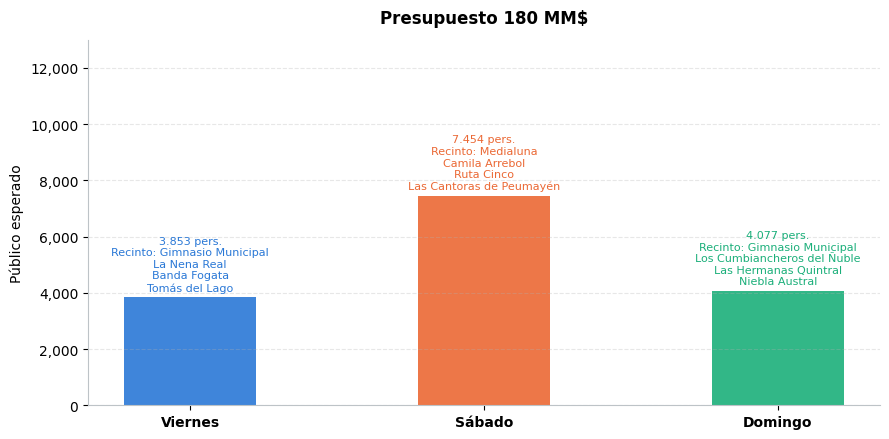


  PRESUPUESTO: 220 MM$

  Noche      Recinto               Público   Artistas
  --------------------------------------------------------------------------------
  Viernes    Medialuna               7,005   Los Volcanes, Los Cumbiancheros del Ñuble, Yisus Beat
  Sábado     Medialuna               7,500   Kevo Flow, Niebla Austral, Tomás del Lago
  Domingo    Gimnasio Municipal      4,127   Las Hermanas Quintral, Ruta Cinco, Banda Fogata
  --------------------------------------------------------------------------------
  Público total:      18,632 personas
  Costo total:           220 MM$
  Plan seguridad:   NO


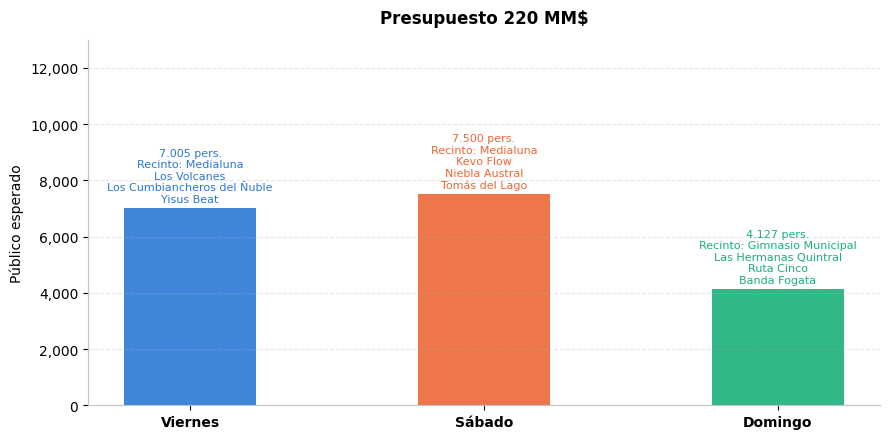


  PRESUPUESTO: 260 MM$

  Noche      Recinto               Público   Artistas
  --------------------------------------------------------------------------------
  Viernes    Medialuna               7,153   Kevo Flow, Ruta Cinco, Las Cantoras de Peumayén
  Sábado     Plaza de Armas          9,514   Los Volcanes, Los Cumbiancheros del Ñuble, La Nena Real
  Domingo    Gimnasio Municipal      3,333   Grupo Tierra Sur, Las Hermanas Quintral, Niebla Austral
  --------------------------------------------------------------------------------
  Público total:      20,000 personas
  Costo total:           252 MM$
  Plan seguridad:   NO


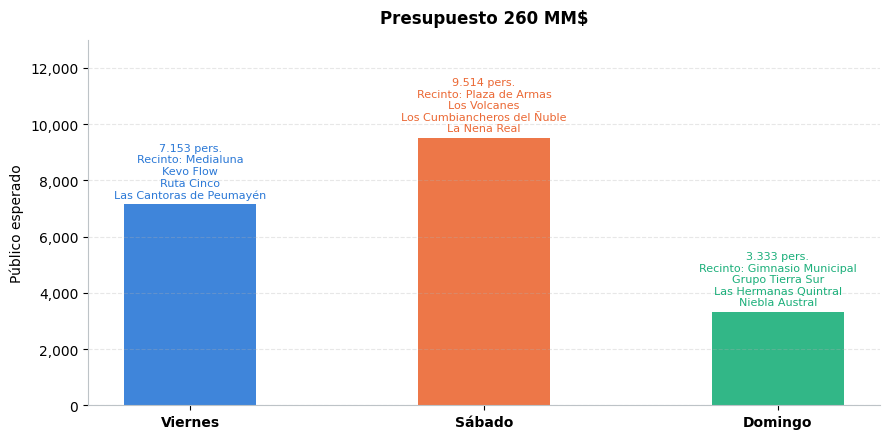


  PRESUPUESTO: 300 MM$

  Noche      Recinto               Público   Artistas
  --------------------------------------------------------------------------------
  Viernes    Medialuna               7,350   Camila Arrebol, Ruta Cinco, Banda Fogata
  Sábado     Medialuna               7,500   Kevo Flow, Niebla Austral, Tomás del Lago
  Domingo    Medialuna               7,500   Los Volcanes, Los Cumbiancheros del Ñuble, Las Hermanas Quintral
  --------------------------------------------------------------------------------
  Público total:      22,350 personas
  Costo total:           297 MM$
  Plan seguridad:   SÍ


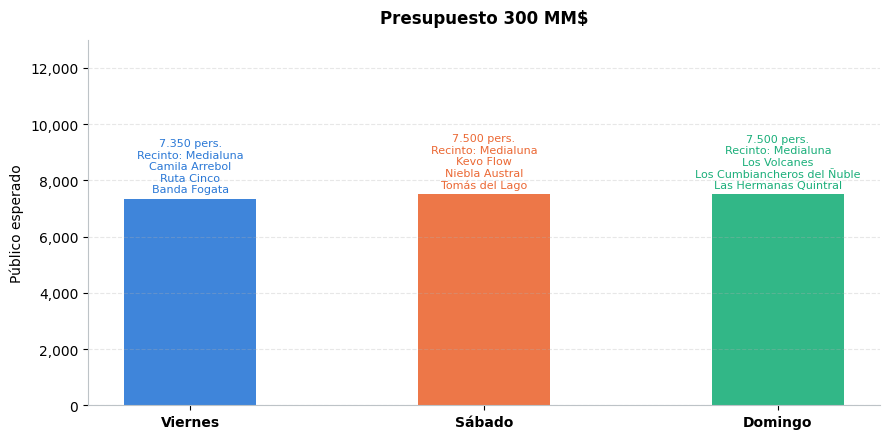


  PRESUPUESTO: 340 MM$

  Noche      Recinto               Público   Artistas
  --------------------------------------------------------------------------------
  Viernes    Medialuna               7,252   Los Volcanes, La Nena Real, Banda Fogata
  Sábado     Plaza de Armas         10,730   Kevo Flow, Los Cumbiancheros del Ñuble, Las Hermanas Quintral
  Domingo    Medialuna               7,273   Camila Arrebol, Grupo Tierra Sur, Ruta Cinco
  --------------------------------------------------------------------------------
  Público total:      25,255 personas
  Costo total:           332 MM$
  Plan seguridad:   SÍ


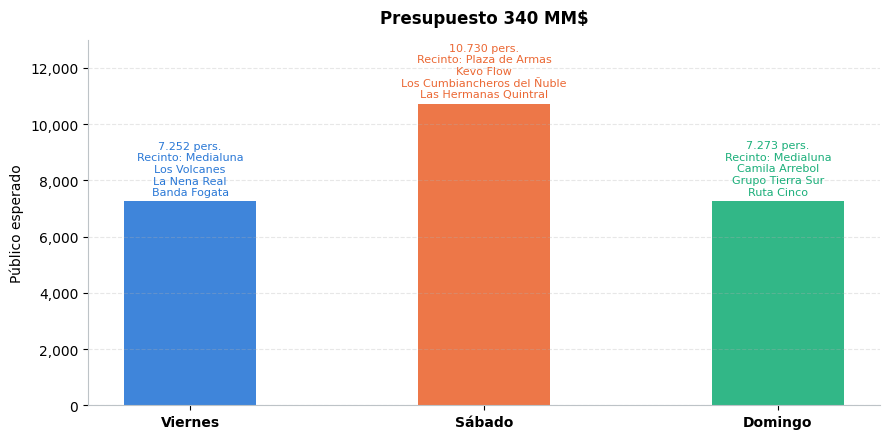

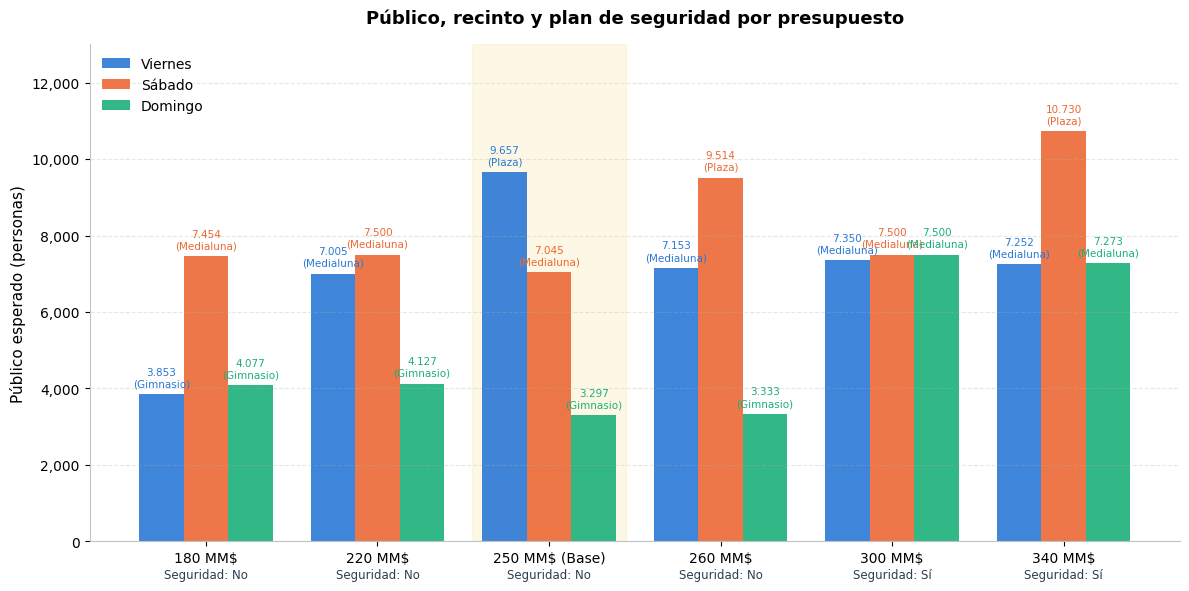

In [ ]:
# -------------------------------------------------------------------------
# LIBRERÍAS
# -------------------------------------------------------------------------
from itertools import combinations
import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt
import numpy as np

# Paleta de colores unificada para todo el script
COLORES_NOCHES = {
    "Viernes": "#2a78d6",
    "Sábado": "#eb6834",
    "Domingo": "#1baf7a",
}


# Función personalizada para mostrar la parrilla de cada presupuesto con los colores correctos
def mostrar_parrilla_personalizada(parrilla, titulo=""):
  noches = ["Viernes", "Sábado", "Domingo"]
  datos_noche = {}

  for n, r, arts in parrilla:
    p = round(min(FACTOR_NOCHE[n] * demanda(arts), RECINTOS[r]["capacidad"]))
    datos_noche[n] = {"publico": p, "recinto": r, "artistas": arts}

  fig, ax = plt.subplots(figsize=(9, 4.5))
  x = np.arange(len(noches))

  vals = [datos_noche[n]["publico"] for n in noches]
  colores_barras = [COLORES_NOCHES[n] for n in noches]

  barras = ax.bar(
      x, vals, color=colores_barras, width=0.45, alpha=0.9, linewidth=0
  )

  for j, rect in enumerate(barras):
    altura = rect.get_height()
    n = noches[j]
    rec = recs = datos_noche[n]["recinto"]
    artistas_txt = "\n".join(datos_noche[n]["artistas"])

    ax.text(
        rect.get_x() + rect.get_width() / 2,
        altura + 150,
        f"{altura:,} pers.\nRecinto: {rec}\n{artistas_txt}".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=8,
        color=colores_barras[j],
        fontweight="medium",
    )

  ax.set_xticks(x)
  ax.set_xticklabels(noches, fontsize=10, fontweight="bold")
  ax.set_ylabel("Público esperado", fontsize=10)
  ax.set_title(titulo, fontsize=12, fontweight="bold", pad=12)
  ax.set_ylim(0, 13000)
  ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))

  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  ax.spines["left"].set_color("#bdc3c7")
  ax.spines["bottom"].set_color("#bdc3c7")
  ax.grid(axis="y", linestyle="--", alpha=0.3)

  plt.tight_layout()
  plt.show()


# -------------------------------------------------------------------------
# 1. Conjuntos y parámetros precalculados
# -------------------------------------------------------------------------
A = list(ARTISTAS)
N = NOCHES
R = list(RECINTOS)
C = list(combinations(A, 3))
K = range(len(C))
M_BIG = 16000

P = {
    (k, n, r): round(
        min(FACTOR_NOCHE[n] * demanda(C[k]), RECINTOS[r]["capacidad"])
    )
    for k in K
    for n in N
    for r in R
}

# -------------------------------------------------------------------------
# 2. Loop sobre presupuestos
# -------------------------------------------------------------------------
PRESUPUESTOS = [180, 220, 260, 300, 340]
resultados = {}

for presupuesto in PRESUPUESTOS:
  print(f'\n{"="*70}')
  print(f"  PRESUPUESTO: {presupuesto} MM$")
  print(f'{"="*70}')

  model = gp.Model(f"Fiesta_de_Verano_{presupuesto}")
  model.Params.OutputFlag = 0
  model.Params.MIPGap = 0

  X = {
      (k, n, r): model.addVar(vtype=GRB.BINARY, name=f"X_{k}_{i}_{j}")
      for k in K
      for i, n in enumerate(N)
      for j, r in enumerate(R)
  }

  Y = {
      a: model.addVar(vtype=GRB.BINARY, name=f"Y_{i+1}")
      for i, a in enumerate(A)
  }

  S = model.addVar(vtype=GRB.BINARY, name="S")

  publico_total = gp.quicksum(
      P[k, n, r] * X[k, n, r] for k in K for n in N for r in R
  )
  costo_artistas = gp.quicksum(ARTISTAS[a]["costo"] * Y[a] for a in A)
  costo_recintos = gp.quicksum(
      RECINTOS[r]["costo"] * X[k, n, r] for k in K for n in N for r in R
  )
  costo_total = costo_artistas + costo_recintos + COSTO_SEGURIDAD * S

  # Restricciones
  for i, n in enumerate(N):
    model.addConstr(
        gp.quicksum(X[k, n, r] for k in K for r in R) == 1,
        name=f"una_terna_{i+1}",
    )

  for i, a in enumerate(A):
    model.addConstr(
        Y[a]
        == gp.quicksum(
            X[k, n, r] for k in K if a in C[k] for n in N for r in R
        ),
        name=f"contratacion_{i+1}",
    )

  for i, a in enumerate(A):
    for j, n in enumerate(N):
      disponible = int(n in ARTISTAS[a]["noches"])
      model.addConstr(
          gp.quicksum(X[k, n, r] for k in K if a in C[k] for r in R)
          <= disponible,
          name=f"disponibilidad_{i+1}_{j+1}",
      )

  for i, n in enumerate(N):
    model.addConstr(
        gp.quicksum(
            X[k, n, r] for k in K if "La Sonora Copihue" in C[k] for r in R
        )
        <= gp.quicksum(
            X[k, n, r] for k in K if "Banda Fogata" in C[k] for r in R
        ),
        name=f"telonero_{i+1}",
    )

  model.addConstr(Y["La Nena Real"] + Y["Yisus Beat"] <= 1, name="exclusion")
  model.addConstr(
      publico_total - UMBRAL_SEGURIDAD <= M_BIG * S,
      name="seguridad_obligatoria",
  )
  model.addConstr(
      publico_total >= (UMBRAL_SEGURIDAD + 1) * S,
      name="seguridad_solo_si_corresponde",
  )
  model.addConstr(costo_total <= presupuesto, name="presupuesto")

  # Optimización Etapa 1
  model.setObjective(publico_total, GRB.MAXIMIZE)
  model.optimize()

  if model.Status != GRB.OPTIMAL:
    print(f"  Sin solución óptima para presupuesto {presupuesto} MM$.")
    resultados[presupuesto] = None
    continue

  mejor_publico = round(model.ObjVal)

  # Optimización Etapa 2 (Desempate)
  model.addConstr(publico_total == mejor_publico, name="fijar_publico_optimo")
  model.setObjective(costo_total, GRB.MINIMIZE)
  model.optimize()

  if model.Status != GRB.OPTIMAL:
    print(f"  No se demostró optimalidad en la segunda etapa.")
    resultados[presupuesto] = None
    continue

  parrilla = []
  for n in N:
    for k in K:
      for r in R:
        if X[k, n, r].X > 0.5:
          parrilla.append((n, r, list(C[k])))
          break

  publico_por_noche = {}
  for n, r, artistas in parrilla:
    p = round(min(FACTOR_NOCHE[n] * demanda(artistas), RECINTOS[r]["capacidad"]))
    publico_por_noche[n] = {"publico": p, "recinto": r, "artistas": artistas}

  seguridad_val = S.X > 0.5
  publico_total_val = round(publico_total.getValue())
  costo_total_val = round(costo_total.getValue())

  resultados[presupuesto] = {
      "publico_total": publico_total_val,
      "costo_total": costo_total_val,
      "seguridad": seguridad_val,
      "publico_por_noche": publico_por_noche,
  }

  print(f'\n  {"Noche":<10} {"Recinto":<20} {"Público":>8}   Artistas')
  print(f'  {"-"*80}')
  for n in N:
    d = publico_por_noche[n]
    nombres = ", ".join(d["artistas"])
    print(f'  {n:<10} {d["recinto"]:<20} {d["publico"]:>8,}   {nombres}')
  print(f'  {"-"*80}')
  print(f"  Público total:    {publico_total_val:>8,} personas")
  print(f"  Costo total:      {costo_total_val:>8} MM$")
  print(f'  Plan seguridad:   {"SÍ" if seguridad_val else "NO"}')

  # Usar el gráfico chico personalizado con los colores correctos
  mostrar_parrilla_personalizada(
      parrilla, titulo=f"Presupuesto {presupuesto} MM$"
  )


# -------------------------------------------------------------------------
# 3. Gráfico Resumen Final (Estilo limpio, sin bordes negros, texto en negro)
# -------------------------------------------------------------------------
presupuestos_lbl = [
    "180 MM$",
    "220 MM$",
    "250 MM$ (Base)",
    "260 MM$",
    "300 MM$",
    "340 MM$",
]

publico_resumen = {
    "Viernes": [3853, 7005, 9657, 7153, 7350, 7252],
    "Sábado": [7454, 7500, 7045, 9514, 7500, 10730],
    "Domingo": [4077, 4127, 3297, 3333, 7500, 7273],
}

recintos_resumen = {
    "Viernes": [
        "Gimnasio",
        "Medialuna",
        "Plaza",
        "Medialuna",
        "Medialuna",
        "Medialuna",
    ],
    "Sábado": ["Medialuna", "Medialuna", "Medialuna", "Plaza", "Medialuna", "Plaza"],
    "Domingo": [
        "Gimnasio",
        "Gimnasio",
        "Gimnasio",
        "Gimnasio",
        "Medialuna",
        "Medialuna",
    ],
}

seguridad_resumen = [
    "Seguridad: No",
    "Seguridad: No",
    "Seguridad: No",
    "Seguridad: No",
    "Seguridad: Sí",
    "Seguridad: Sí",
]

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(presupuestos_lbl))
ancho = 0.26
idx_base = 2

for i, (noche, valores) in enumerate(publico_resumen.items()):
  offset = (i - 1) * ancho
  barras = ax.bar(
      x + offset,
      valores,
      ancho,
      label=noche,
      color=COLORES_NOCHES[noche],
      alpha=0.9,
      linewidth=0,  # Sin borde negro
  )

  for j, rect in enumerate(barras):
    altura = rect.get_height()
    recinto_corto = recintos_resumen[noche][j]

    ax.text(
        rect.get_x() + rect.get_width() / 2,
        altura + 150,
        f"{altura:,}\n({recinto_corto})".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=7.5,
        color=COLORES_NOCHES[noche],
        fontweight="medium",
    )

# Banda sutil para el escenario base
ax.axvspan(idx_base - 0.45, idx_base + 0.45, color="#f1c40f", alpha=0.1, zorder=0)

# Indicador de seguridad en color negro/gris oscuro
for xi, seg in zip(x, seguridad_resumen):
  ax.text(
      xi,
      -700,
      seg,
      ha="center",
      va="top",
      fontsize=8.5,
      color="#2c3e50",
      fontweight="medium",
  )

ax.set_xticks(x)
ax.set_xticklabels(presupuestos_lbl, fontsize=10)
ax.set_ylabel("Público esperado (personas)", fontsize=11)
ax.set_title(
    "Público, recinto y plan de seguridad por presupuesto",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

ax.set_ylim(0, 13000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))

ax.legend(loc="upper left", frameon=False, fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#bdc3c7")
ax.spines["bottom"].set_color("#bdc3c7")

plt.tight_layout()
plt.show()

Adicionalmente, se realizó una tabla para visualizar claramente las soluciones de cada presupuesto.

*Declaración de IA: Para la realización de este código se utilizó Gemini.

In [ ]:
from IPython.display import display, HTML

display(HTML("""
<table border="1" style="border-collapse:collapse; font-family:Arial; font-size:13px; width:100%">
  <thead>
    <tr style="background-color:#1565c0; color:white; text-align:center">
      <th style="padding:8px">Presupuesto (MM$)</th>
      <th style="padding:8px">Noche</th>
      <th style="padding:8px">Recinto</th>
      <th style="padding:8px">Público por noche</th>
      <th style="padding:8px">Público total</th>
      <th style="padding:8px">Plan de seguridad</th>
    </tr>
  </thead>
  <tbody>

    <tr><td rowspan="3" style="text-align:center; padding:8px"><b>180</b></td><td style="padding:8px">Viernes</td><td style="padding:8px">Gimnasio Municipal</td><td style="text-align:center; padding:8px">3.853</td><td rowspan="3" style="text-align:center; padding:8px"><b>15.384</b></td><td rowspan="3" style="text-align:center; padding:8px">No</td></tr>
    <tr><td style="padding:8px">Sábado</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.454</td></tr>
    <tr><td style="padding:8px">Domingo</td><td style="padding:8px">Gimnasio Municipal</td><td style="text-align:center; padding:8px">4.077</td></tr>

    <tr><td rowspan="3" style="text-align:center; padding:8px"><b>220</b></td><td style="padding:8px">Viernes</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.005</td><td rowspan="3" style="text-align:center; padding:8px"><b>18.632</b></td><td rowspan="3" style="text-align:center; padding:8px">No</td></tr>
    <tr><td style="padding:8px">Sábado</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.500</td></tr>
    <tr><td style="padding:8px">Domingo</td><td style="padding:8px">Gimnasio Municipal</td><td style="text-align:center; padding:8px">4.127</td></tr>

    <tr style="background-color:#fff9e6"><td rowspan="3" style="text-align:center; padding:8px"><b>250</b> </td><td style="padding:8px">Viernes</td><td style="padding:8px">Plaza de Armas</td><td style="text-align:center; padding:8px">9.657</td><td rowspan="3" style="text-align:center; padding:8px"><b>19.999</b></td><td rowspan="3" style="text-align:center; padding:8px">No</td></tr>
    <tr style="background-color:#fff9e6"><td style="padding:8px">Sábado</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.045</td></tr>
    <tr style="background-color:#fff9e6"><td style="padding:8px">Domingo</td><td style="padding:8px">Gimnasio Municipal</td><td style="text-align:center; padding:8px">3.297</td></tr>

    <tr><td rowspan="3" style="text-align:center; padding:8px"><b>260</b></td><td style="padding:8px">Viernes</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.153</td><td rowspan="3" style="text-align:center; padding:8px"><b>20.000</b></td><td rowspan="3" style="text-align:center; padding:8px">No</td></tr>
    <tr><td style="padding:8px">Sábado</td><td style="padding:8px">Plaza de Armas</td><td style="text-align:center; padding:8px">9.514</td></tr>
    <tr><td style="padding:8px">Domingo</td><td style="padding:8px">Gimnasio Municipal</td><td style="text-align:center; padding:8px">3.333</td></tr>

    <tr><td rowspan="3" style="text-align:center; padding:8px"><b>300</b></td><td style="padding:8px">Viernes</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.350</td><td rowspan="3" style="text-align:center; padding:8px"><b>22.350</b></td><td rowspan="3" style="text-align:center; padding:8px">Sí</td></tr>
    <tr><td style="padding:8px">Sábado</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.500</td></tr>
    <tr><td style="padding:8px">Domingo</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.500</td></tr>

    <tr><td rowspan="3" style="text-align:center; padding:8px"><b>340</b></td><td style="padding:8px">Viernes</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.252</td><td rowspan="3" style="text-align:center; padding:8px"><b>25.255</b></td><td rowspan="3" style="text-align:center; padding:8px">Sí</td></tr>
    <tr><td style="padding:8px">Sábado</td><td style="padding:8px">Plaza de Armas</td><td style="text-align:center; padding:8px">10.730</td></tr>
    <tr><td style="padding:8px">Domingo</td><td style="padding:8px">Medialuna</td><td style="text-align:center; padding:8px">7.273</td></tr>

  </tbody>
</table>
"""))

## *Pregunta II.*

***Pregunta II.***\
*¿Qué noche queda más desmejorada? Explique por qué ocurre esto a partir de la formulación de su modelo.*

Para analizar qué noche queda más desmejorada, se realizará un gráfico que permitirá visualizar los datos pertinentes para responder.

*Declaración de IA: Para la realización de este código se utilizó Gemini.

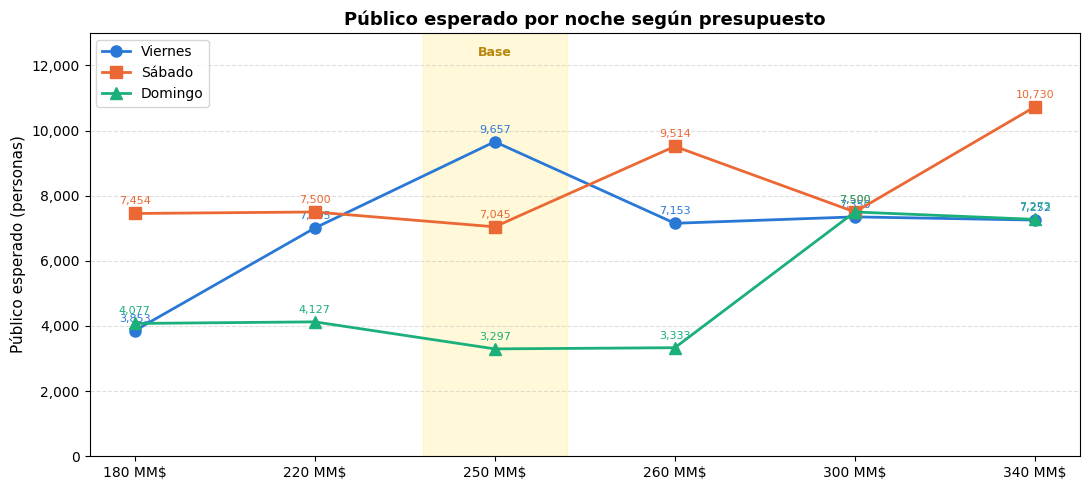

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------------------------------
# Datos
# -------------------------------------------------------------------------
presupuestos = ['180 MM$', '220 MM$', '250 MM$', '260 MM$', '300 MM$', '340 MM$']
publico = {
    'Viernes': [3853, 7005, 9657, 7153, 7350, 7252],
    'Sábado':  [7454, 7500, 7045, 9514, 7500, 10730],
    'Domingo': [4077, 4127, 3297, 3333, 7500, 7273],
}
colores  = {'Viernes': '#2a78d6', 'Sábado': '#eb6834', 'Domingo': '#1baf7a'}
marcador = {'Viernes': 'o',       'Sábado': 's',       'Domingo': '^'}

idx_base = 2  # posición del presupuesto base (250 MM$)

# -------------------------------------------------------------------------
# Gráfico
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(presupuestos))

for noche, valores in publico.items():
    ax.plot(x, valores,
            color=colores[noche],
            marker=marcador[noche],
            markersize=8,
            linewidth=2,
            label=noche,
            zorder=3)
    for xi, val in zip(x, valores):
        ax.text(xi, val + 220, f'{val:,}',
                ha='center', va='bottom',
                fontsize=8, color=colores[noche])

# Banda vertical destacando el presupuesto base
ax.axvspan(idx_base - 0.4, idx_base + 0.4,
           color='gold', alpha=0.15, zorder=1)
ax.text(idx_base, 12600, 'Base', ha='center', va='top',
        fontsize=9, color='#b8860b', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(presupuestos, fontsize=10)
ax.set_ylabel('Público esperado (personas)', fontsize=11)
ax.set_title('Público esperado por noche según presupuesto', fontsize=13, fontweight='bold')
ax.set_ylim(0, 13000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{int(v):,}'))
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

A partir del gráfico anterior es posible observar que en la mayoría de los casos (en 4 de los 7 presupuestos analizados) la noche que queda más desmejorada es el **Domingo**. Los públicos totales para el día son menores, o, a lo más, aproximadamente equivalentes con las otras noches, y en términos de diferencia, el domingo presenta una mayor diferencia de público con el día de mayor demanda (sábado).

Esto se debe a que el modelo planteado tiene una única restricción sujeta al presupuesto, la que no busca gastarlo equitativamente entre los tres días, sino que la función objetivo busca optimizar lo más posible el público total entre los tres días. Es por esto mismo que la distribución de presupuesto se ve condicionada por el factor $Ø𝑛$, que provoca que el presupuesto gastado "pese" más en su efecto en la demanda si es gastado el sábado, con un factor de $Ø𝑛=1$, luego el viernes, con un factor de $Ø𝑛=0,9$, y finalmente el domingo, con un factor $Ø𝑛=0,85$. Este factor está incluido dentro de la definición del parámetro $P_{𝑐,𝑛,𝑟}$, que se calcula a partir de la fórmula $𝑚𝑖𝑛(Ø𝑛⋅𝐷(𝑐),𝐾𝑟)$, y este determina el público esperado. Luego, este parámetro se utiliza posteriormente en la función objetivo. Es por esto que al resolver conviene invertir en el sábado, luego el viernes y finalmente el domingo.

Siendo así, cuando hay un menor presupuesto el sistema prioriza invertir en artistas más caros y populares para el sábado, y luego en menor medida el viernes, lo cual tiende a dejar al domingo con los artistas restantes, que son más baratos, pero también son menos populares, condicionando una menor demanda, en general, para el domingo.

Es posible que en algunos casos la noche más desmejorada sea el viernes, como se observa en el gráfico, pero según la lógica de la función planteada, la prioridad del algoritmo siempre será dejar mejores artistas el viernes que el domingo, siendo circunstancial esta condición.


## *Pregunta III*

***Pregunta III.***\
*Proponga una o más condiciones que permitan mejorar la situación de la noche más desmejorada sin aumentar el presupuesto de $250$ MM$. Incorpórelas al modelo, resuélvalo y compare sus efectos sobre el público de cada noche y el público total.*

Para mejorar la situación más desmejorada que, a partir del inciso anterior se afirmó que era el día domingo, se agregan las siguientes condiciones al modelo:

<br>

**Cantidad mínima**

Se exige que la cantidad de asistentes del día domingo sea al menos $Q_{min}$ personas (valor a convenir).

$$\sum_{r \in R} \sum_{c \in C} P_{c, \text{ Domingo}, \ r} \cdot X_{c, \text{ Domingo}, \ r} \ge Q_{\min}$$
<center> $Q_{min}$: Cantidad mínima de personas de público esperado que se exige para el día Domingo</center>

**Explicación de la restricción* :\
A partir de la sumatoria doble se buscan todas las combinaciones de cualquier recinto disponible que permitan que el público esperado para el día domingo sea mayor o igual a $Q_{min}$, siendo este valor definido en el mismo código.

<br>

**Diferencia respecto al día con mayor cantidad de asistencia**

Se exige que el día con menor asistencia (que es el día domingo normalmente) no asista menos de $\beta$  de los otros días con más asistentes.

$$\sum_{r \in R} \sum_{c \in C} P_{c, \text{ Domingo}, \ r} \cdot X_{c, \text{ Domingo}, \ r} \ge \beta \cdot \left( \sum_{r \in R} \sum_{c \in C} P_{c, n , r} \cdot X_{c, n , r} \right)$$
<center> $\forall n \in N - \{Domingo\}$</center>

<center> $ \beta \in [0,1]$, donde $\beta$ representa la proporción/fracción mínima del público de las otras noches que se exige alcanzar el domingo.</center>

**Explicación de la restricción* :\
Esta restricción

<br>

**Presencia de artista de nivel grande**

Se exige que el día domingo tenga por lo menos un artista de nivel grande para generar arrastre, es decir, mejorar la asistencia a partir de la presencia de un artista grande (que incrementa la demanda base en un $20 \% $).

Definamos $C_G \subseteq C$ como el subconjunto de combinaciones de artistas que contienen al menos un artista cuyo nivel sea 'G'

$$\sum_{r \in R} \sum_{c \in C_G} X_{c, \text{ Domingo}, \ r} = 1$$

**Explicación de la restricción* :\
Esta restricción busca redefinir que cada noche tenga exactamente una combinación de artistas y un recinto (restricción $(1)$ definida en el item $a$), cambiando que para el día Domingo la combinación de artistas seleccionada contenga al menos un artista grande.\
Cabe destacar que, esta restricción no garantiza un público mínimo para el domingo, pero sí busca aumentar la asistencia del público esperado para aquel día.

Para la resolución de este inciso, se analizarán las tres restricciones por separado para comparar y analizar cuál alternativa cumple de mejor manera lo buscado.\
Para el código se considerarán los siguientes valores:
* $Q_{min}=5000$
  * Explicación: El público asistente para el día Domingo tiene que ser mayor o igual a $5000$ personas.
* $\beta = 0,5$
  * Explicación: La asistencia del domingo tenga al menos el $50 \%$ del público esperado para el viernes y el sábado.
* $Presupuesto = 250$ *MM\$*

*Declaración de IA: Para la realización de este código se utilizó ChatGPT.

In [ ]:
from itertools import combinations
import gurobipy as gp
from gurobipy import GRB

# ============================================================================
# 1. VALORES DE LAS CONDICIONES QUE QUEREMOS COMPARAR (EDITABLES)
# ============================================================================
Q_MIN = 8000       # Asistencia minima exigida el domingo (personas)
BETA = 0.75        # Domingo >= 75 % de viernes Y >= 75 % de sabado
DOMINGO = 'Domingo'

# ============================================================================
# 2. CONJUNTOS Y PARAMETROS (SE CALCULAN SOLO UNA VEZ)
# ============================================================================
A = list(ARTISTAS)
N = list(NOCHES)
R = list(RECINTOS)
C = list(combinations(A, 3))
K = range(len(C))

# Indices de combinaciones que incluyen al artista a.
K_POR_ARTISTA = {
    a: [k for k in K if a in C[k]] for a in A
}

# Combinaciones con al menos un artista grande.
C_G = [
    k for k in K
    if any(ARTISTAS[a]['nivel'] == 'G' for a in C[k])
]

# Demanda precalculada de cada terna y publico por noche y recinto.
D = {k: demanda(C[k]) for k in K}
P = {
    (k, n, r): round(min(
        FACTOR_NOCHE[n] * D[k], RECINTOS[r]['capacidad']
    ))
    for k in K for n in N for r in R
}

# Big-M ajustado a la mayor asistencia fisicamente posible.
M = len(N) * max(RECINTOS[r]['capacidad'] for r in R) - UMBRAL_SEGURIDAD


def resolver_escenario(nombre, condicion=None, valor=None):
    """Resuelve una alternativa y devuelve publico/costo/parrilla optimos."""
    m = gp.Model('Festival_d_iii')
    m.Params.OutputFlag = 0
    m.Params.MIPGap = 0

    # ------------------------------------------------------------------------
    # 3. VARIABLES BINARIAS
    # ------------------------------------------------------------------------
    X = {
        (k, n, r): m.addVar(vtype=GRB.BINARY, name=f'X_{k}_{i}_{j}')
        for k in K
        for i, n in enumerate(N)
        for j, r in enumerate(R)
    }
    Y = {
        a: m.addVar(vtype=GRB.BINARY, name=f'Y_{i+1}')
        for i, a in enumerate(A)
    }
    S = m.addVar(vtype=GRB.BINARY, name='S')

    # ------------------------------------------------------------------------
    # 4. PUBLICO Y COSTO
    # ------------------------------------------------------------------------
    publico_total = gp.quicksum(
        P[k, n, r] * X[k, n, r] for k in K for n in N for r in R
    )
    costo_artistas = gp.quicksum(ARTISTAS[a]['costo'] * Y[a] for a in A)
    costo_recintos = gp.quicksum(
        RECINTOS[r]['costo'] * X[k, n, r]
        for k in K for n in N for r in R
    )
    costo_total = costo_artistas + costo_recintos + COSTO_SEGURIDAD * S

    # ------------------------------------------------------------------------
    # 5. RESTRICCIONES ORIGINALES (ITEM a)
    # ------------------------------------------------------------------------
    # Cada noche: exactamente una terna y un recinto.
    for i, n in enumerate(N):
        m.addConstr(
            gp.quicksum(X[k, n, r] for k in K for r in R) == 1,
            name=f'Una_terna_{i+1}',
        )

    # Y[a]=1 si a es contratado; al ser binaria, evita repeticiones.
    for i, a in enumerate(A):
        m.addConstr(
            Y[a] == gp.quicksum(
                X[k, n, r]
                for k in K_POR_ARTISTA[a] for n in N for r in R
            ),
            name=f'Contratacion_{i+1}',
        )

    # Disponibilidad por artista y noche.
    for i, a in enumerate(A):
        for j, n in enumerate(N):
            disp = int(n in ARTISTAS[a]['noches'])
            m.addConstr(
                gp.quicksum(
                    X[k, n, r] for k in K_POR_ARTISTA[a] for r in R
                ) <= disp,
                name=f'Disponibilidad_{i+1}_{j+1}',
            )

    # La Sonora Copihue -> Banda Fogata, la misma noche.
    for i, n in enumerate(N):
        m.addConstr(
            gp.quicksum(
                X[k, n, r] for k in K_POR_ARTISTA['La Sonora Copihue'] for r in R
            ) <= gp.quicksum(
                X[k, n, r] for k in K_POR_ARTISTA['Banda Fogata'] for r in R
            ),
            name=f'Telonero_{i+1}',
        )

    # Artistas incompatibles en el festival.
    m.addConstr(Y['La Nena Real'] + Y['Yisus Beat'] <= 1, name='Exclusion')

    # Plan de seguridad basado en la asistencia NOMINAL del festival.
    m.addConstr(
        publico_total - UMBRAL_SEGURIDAD <= M * S,
        name='Seguridad_obligatoria',
    )
    m.addConstr(
        publico_total >= (UMBRAL_SEGURIDAD + 1) * S,
        name='Seguridad_solo_si_corresponde',
    )

    # Presupuesto de 250 MM$; no se modifica entre escenarios.
    m.addConstr(costo_total <= PRESUPUESTO, name='Presupuesto')

    # ------------------------------------------------------------------------
    # 6. NUEVA CONDICION DEL ITEM d.iii (SOLO UNA POR ESCENARIO)
    # ------------------------------------------------------------------------
    publico_domingo = gp.quicksum(
        P[k, DOMINGO, r] * X[k, DOMINGO, r]
        for k in K for r in R
    )

    if condicion == 'minimo':
        # Domingo debe alcanzar por lo menos Q_MIN personas.
        m.addConstr(publico_domingo >= valor, name='Minimo_domingo')

    elif condicion == 'relativo':
        # Domingo >= beta * viernes y domingo >= beta * sabado.
        for i, n in enumerate(n for n in N if n != DOMINGO):
            publico_noche = gp.quicksum(
                P[k, n, r] * X[k, n, r] for k in K for r in R
            )
            m.addConstr(
                publico_domingo >= valor * publico_noche,
                name=f'Equilibrio_{i+1}',
            )

    elif condicion == 'grande':
        # El domingo se elige una terna que contiene al menos un grande.
        m.addConstr(
            gp.quicksum(
                X[k, DOMINGO, r] for k in C_G for r in R
            ) == 1,
            name='Grande_domingo',
        )

    elif condicion is not None:
        raise ValueError(f'Condicion desconocida: {condicion}')

    # ------------------------------------------------------------------------
    # 7. OPTIMIZACION 1: MAXIMIZAR EL PUBLICO
    # ------------------------------------------------------------------------
    m.setObjective(publico_total, GRB.MAXIMIZE)
    m.optimize()
    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(f'No se demostro optimalidad al maximizar: {nombre}')
    publico_optimo = round(m.ObjVal)

    # ------------------------------------------------------------------------
    # 8. OPTIMIZACION 2: FIJAR EL PUBLICO Y MINIMIZAR EL COSTO
    # ------------------------------------------------------------------------
    m.addConstr(publico_total == publico_optimo, name='Fijar_publico')
    m.setObjective(costo_total, GRB.MINIMIZE)
    m.optimize()
    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(f'No se demostro optimalidad al minimizar: {nombre}')

    # Extraer parrilla en el orden original de las noches.
    parrilla = []
    for n in N:
        elegidas = [
            (n, r, list(C[k]), P[k, n, r])
            for k in K for r in R if X[k, n, r].X > 0.5
        ]
        if len(elegidas) != 1:
            raise RuntimeError(f'Debe haber una seleccion por noche: {n}')
        parrilla.extend(elegidas)

    return {
        'escenario': nombre,
        'publico': int(round(publico_total.getValue())),
        'costo': int(round(costo_total.getValue())),
        'seguridad': S.X > 0.5,
        'parrilla': parrilla,
        'por_noche': {n: p for n, r, c, p in parrilla},
    }


# ============================================================================
# 9. RESOLVER ESCENARIOS POR SEPARADO
# ============================================================================
escenarios = [
    ('Base (250 MM$)', None, None),
    (f'Domingo >= {Q_MIN}', 'minimo', Q_MIN),
    (f'Domingo >= {BETA:.0%} de otras', 'relativo', BETA),
    ('Artista grande domingo', 'grande', None),
]

resultados = [resolver_escenario(*args) for args in escenarios]
base = resultados[0]

# ============================================================================
# 10. TABLA COMPARATIVA TOTAL
# ============================================================================
print('\n' + '=' * 106)
print('COMPARACION DE CONDICIONES ( CON PRESUPUESTO DE 250 MM$)')
print('=' * 106)
print(
    f"{'ESCENARIO':<29}{'PUBLICO TOTAL':>15}{'DOMINGO':>12}"
    f"{'COSTO MM$':>14}{'DIF. TOTAL':>15}{'DIF. DOM.':>14}{'SEGURIDAD':>12}"
)
print('-' * 113)
for res in resultados:
    dif_total = f"{res['publico']-base['publico']:+,d}"
    dif_dom = f"{res['por_noche'][DOMINGO]-base['por_noche'][DOMINGO]:+,d}"
    print(
        f"{res['escenario']:<29}{res['publico']:>15,d}"
        f"{res['por_noche'][DOMINGO]:>12,d}{res['costo']:>14,d}"
        f"{dif_total:>15}{dif_dom:>14}"
        f"{('Si' if res['seguridad'] else 'No'):>12}"
    )

# ============================================================================
# 11. COMPARACION DEL PUBLICO POR NOCHE
# ============================================================================
print('\nPUBLICO POR NOCHE (PERSONAS)')
print(f"{'NOCHE':<12}" + ''.join(f"{r['escenario']:>27}" for r in resultados))
print('-' * (12 + 27 * len(resultados)))
for n in N:
    print(f"{n:<12}" + ''.join(f"{r['por_noche'][n]:>27,d}" for r in resultados))

# ============================================================================
# 12. PARRILLAS: ARTISTAS Y RECINTO PARA CADA ALTERNATIVA
# ============================================================================
for res in resultados:
    print('\n' + '=' * 90)
    print('PARRILLA - ' + res['escenario'])
    print('=' * 90)
    for n, r, artistas, p in res['parrilla']:
        print(f'{n.upper()} | {r} | {p:,} personas')
        print('  Artistas: ' + ', '.join(artistas))
    print(
        f"TOTAL: {res['publico']:,} personas | "
        f"COSTO: {res['costo']} MM$ | "
        f"PLAN: {'Si' if res['seguridad'] else 'No'}"
    )


COMPARACION DE CONDICIONES ( CON PRESUPUESTO DE 250 MM$)
ESCENARIO                      PUBLICO TOTAL     DOMINGO     COSTO MM$     DIF. TOTAL     DIF. DOM.   SEGURIDAD
-----------------------------------------------------------------------------------------------------------------
Base (250 MM$)                        19,999       3,297           249             +0            +0          No
Domingo >= 8000                       19,787       8,087           248           -212        +4,790          No
Domingo >= 75% de otras               19,994       5,918           250             -5        +2,621          No
Artista grande domingo                19,998       7,500           244             -1        +4,203          No

PUBLICO POR NOCHE (PERSONAS)
NOCHE                    Base (250 MM$)            Domingo >= 8000    Domingo >= 75% de otras     Artista grande domingo
---------------------------------------------------------------------------------------------------------------------

A partir del modelo resuelto, se obtuvo una tabla al final del código que permite analizar cada alternativa.\
Adicionalmente, se realizó una tabla con la diferencia entre la noche con mayor y menor asistencia, para ver la mejora de las noches desmejoradas.

*Declaración de IA: Para la realización de este código se utilizó ChatGPT.

In [ ]:

# =============================================================================
# COMPARACIÓN DE DIFERENCIAS DE ASISTENCIA ENTRE NOCHES
# =============================================================================

nombres = [
    "Base",
    f"Q_min = {Q_MIN:,}",
    f"Beta = {BETA:.2f}",
    "Artista grande"
]

print("\n" + "=" * 85)
print("COMPARACIÓN DE DIFERENCIAS DE ASISTENCIA ENTRE NOCHES")
print("=" * 85)

# Encabezados
print(
    f"{'ALTERNATIVA':<25}"
    f"{'MAYOR ASISTENCIA':>20}"
    f"{'MENOR ASISTENCIA':>20}"
    f"{'DIFERENCIA':>20}"
)

print("-" * 85)

# Resultados
for nombre, res in zip(nombres, resultados):

    publicos = [res['por_noche'][n] for n in NOCHES]

    mayor = max(publicos)
    menor = min(publicos)
    diferencia = mayor - menor

    print(
        f"{nombre:<25}"
        f"{mayor:>20,d}"
        f"{menor:>20,d}"
        f"{diferencia:>20,d}"
    )

print("=" * 85)



COMPARACIÓN DE DIFERENCIAS DE ASISTENCIA ENTRE NOCHES
ALTERNATIVA                  MAYOR ASISTENCIA    MENOR ASISTENCIA          DIFERENCIA
-------------------------------------------------------------------------------------
Base                                    9,657               3,297               6,360
Q_min = 8,000                           8,087               4,200               3,887
Beta = 0.75                             7,317               5,918               1,399
Artista grande                         10,599               1,899               8,700


Como resultados de cada alternativa podemos destacar que:

* Para $Q_{min}=8000$:
  * Obtiene el mayor aumento de público para el domingo (de $3297$ a $8087$ personas), comparado con las otras alternativas, que consiguen menores aumentos.
  * Disminuye el costo total en $1$ *MM\$*
  * Sin embargo, todo esto lo realiza sacrificando la asistencia total del festival en 212 personas, terminando el público total esperado en $19 \ 787 $ personas.

* Para $\beta= 0,75$:
  * Se obtiene un buen aumento en la asistencia del día domingo obteniendo $5918$ personas.
  * Es la alternativa que presenta la distribución más equilibrada entre las tres noches, obteniendo como mayor diferencia solamente $1399$ personas entre las distintas noches.
  * El público total disminuye solamente en cinco personas, con respecto al modelo base.
  * Sin embargo, el costo total aumenta en $1$ *MM\$*, utilizando la totalidad del presupuesto.

* Para la presencia de un artista grande:
  * Se obtiene un gran aumento para el día domingo de $7500$ personas.
  * Se pierde solamente una persona del público total.
  * Se reduce el costo total en $5$ *MM\$*
  * Pero, produce el mayor desequilibrio entre las noches, pues solamente redirige el problema de la noche más desmejorada para el Viernes, dado que solamente asisten $1899$ personas.

En términos generales, las tres restricciones logran mejorar considerablemente la asistencia del día domingo sin superar el presupuesto establecido, pero presentan distintos efectos.

Por ende, la restricción de proporción mínima ($\beta$), se considera la más adecuada pues es la condición que ofrece una distribución más equilibrada entre las tres noches, manteniendo casi igual la asistencia total del festival, por ende permite resolver en mayor medida el problema de las noches desmejoradas.

Es importante destacar que mejorar una noche en específico (en este caso el domingo), no garantiza que necesariamente va a ocurrir una distribución equilibrada, por ejemplo lo ocurrido con la restricción del artista grande, pues solamente mejoró el domingo dejando como día más desmejorado el viernes, siendo peor que las situaciones iniciales.\
Por lo tanto, es importante considerando tanto la asistencia de cada noche del festival como también el público en la totalidad del evento.



## *Pregunta IV*

***Pregunta IV.*** \
*Para la condición que considere más adecuada, analice cómo cambian los resultados al variar su nivel de exigencia. ¿Cuánto público total se pierde por cada nivel? ¿Qué presupuesto adicional se requeriría para cumplir esa exigencia sin perder público total? A partir de su análisis, recomiende un nivel de exigencia y justifíquelo.*

Para este item, se considerará la restricción de $\beta$, la cual exige que el día con menor asistencia (que es el día domingo normalmente) no asista menos de $\beta$  de los otros días con más asistentes, permitiendo equilibrar la asistencia lo más posible.\
Se utilizarán tres valores para $\beta$, dejando $\beta=0,75$ como valor intermedio:\
$$ \beta \in \{ 0,6 \ ; \ 0,75 \ ; \ 0,9  \}$$

Para el código siguiente se tendrán que realizar dos optimizaciones para cada valor de $\beta$, dado que primeramente se resolverá el modelo manteniendo el presupuesto inicial (250 MM\$), calculando el público alcanzado, y la segunda priorizará mantener el público total de la solución original, generando una posible diferencia en el presupuesto.
En el caso que se observe una disminución del público total con las variaciones de la primera optimización para los distintos $\beta$ se agregará al modelo las siguientes restricciones para la segunda optimización:

* Nuevas restricciones:

$$ P_{total} \ge 19 \ 999$$
<center> Se impone que el público en este modelo sea igual o mayor que el del modelo original, en el cual se obtuvo un público esperado total de $19 \ 999 $ personas. </center>

<br>

$$ \Delta Presupuesto = max\{ 0, C_{min}-250 \} $$

<center> $C_{min}$: Costo total mínimo encontrado que permite mantener el público total. </center>

<center> $Δ Presupuesto$: Incremento del presupuesto con respecto al original. </center>

<center> Se utiliza $max$, dado que si la diferencia entre el costo mínimo y el presupuesto da negativo, equivale que el costo no aumentó.</center>



*Declaración de IA: Para la realización de este código se utilizó ChatGPT.

In [ ]:
from itertools import combinations
import gurobipy as gp
from gurobipy import GRB

A = list(ARTISTAS)
N = list(NOCHES)
R = list(RECINTOS)
C = list(combinations(A, 3))
K = range(len(C))
K_POR_ARTISTA = {a: [k for k in K if a in C[k]] for a in A}
P = {
    (k, n, r): round(min(FACTOR_NOCHE[n] * demanda(C[k]),
                         RECINTOS[r]['capacidad']))
    for k in K for n in N for r in R
}
M = len(N) * max(RECINTOS[r]['capacidad'] for r in R) - UMBRAL_SEGURIDAD

BETAS = [0.60, 0.75, 0.90]
PUBLICO_BASE = 19_999  # Maximo demostrado en el item b)
DOMINGO = 'Domingo'



def crear_modelo_beta(beta, presupuesto=None, publico_minimo=None):
    """Construye de cero el modelo original con la condicion de equilibrio beta."""
    m = gp.Model('Festival_d_iv')
    m.Params.OutputFlag = 0
    m.Params.MIPGap = 0

    X = {
        (k, n, r): m.addVar(vtype=GRB.BINARY, name=f'X_{k}_{i}_{j}')
        for k in K
        for i, n in enumerate(N)
        for j, r in enumerate(R)
    }
    Y = {
        a: m.addVar(vtype=GRB.BINARY, name=f'Y_{i+1}')
        for i, a in enumerate(A)
    }
    S = m.addVar(vtype=GRB.BINARY, name='S')

    # Publico esperado de cada noche y publico total
    publico_noche = {
        n: gp.quicksum(P[k, n, r] * X[k, n, r] for k in K for r in R)
        for n in N
    }
    publico_total = gp.quicksum(publico_noche[n] for n in N)

    # Costo total
    costo_total = (
        gp.quicksum(ARTISTAS[a]['costo'] * Y[a] for a in A)
        + gp.quicksum(
            RECINTOS[r]['costo'] * X[k, n, r]
            for k in K for n in N for r in R
        )
        + COSTO_SEGURIDAD * S
    )

    # Asignacion unica por noche
    for i, n in enumerate(N):
        m.addConstr(
            gp.quicksum(X[k, n, r] for k in K for r in R) == 1,
            name=f'Asignacion_{i+1}'
        )

    # Contratacion unica y vinculacion con la parrilla
    for i, a in enumerate(A):
        m.addConstr(
            Y[a] == gp.quicksum(
                X[k, n, r] for k in K_POR_ARTISTA[a]
                for n in N for r in R
            ),
            name=f'Contratacion_{i+1}'
        )

    # Disponibilidad de artistas
    for i, a in enumerate(A):
        for j, n in enumerate(N):
            m.addConstr(
                gp.quicksum(X[k, n, r] for k in K_POR_ARTISTA[a] for r in R)
                <= int(n in ARTISTAS[a]['noches']),
                name=f'Disponibilidad_{i+1}_{j+1}'
            )

    # Telonero: La Sonora Copihue implica Banda Fogata en la misma noche
    for i, n in enumerate(N):
        m.addConstr(
            gp.quicksum(
                X[k, n, r] for k in K_POR_ARTISTA['La Sonora Copihue'] for r in R
            ) <= gp.quicksum(
                X[k, n, r] for k in K_POR_ARTISTA['Banda Fogata'] for r in R
            ),
            name=f'Telonero_{i+1}'
        )

    # Exclusion
    m.addConstr(Y['La Nena Real'] + Y['Yisus Beat'] <= 1, name='Exclusion')

    # Seguridad
    m.addConstr(publico_total - UMBRAL_SEGURIDAD <= M * S,
                name='Seguridad_obligatoria')
    m.addConstr(publico_total >= (UMBRAL_SEGURIDAD + 1) * S,
                name='Seguridad_solo_si_corresponde')

    # Equilibrio: domingo >= beta * (cada otra noche)
    for i, n in enumerate(n for n in N if n != DOMINGO):
        m.addConstr(
            publico_noche[DOMINGO] >= beta * publico_noche[n],
            name=f'Equilibrio_{i+1}'
        )

    # Segun la etapa: presupuesto fijo o publico minimo fijo
    if presupuesto is not None:
        m.addConstr(costo_total <= presupuesto, name='Presupuesto')
    if publico_minimo is not None:
        m.addConstr(publico_total >= publico_minimo, name='Conservar_publico_base')

    return m, publico_noche, publico_total, costo_total


def resolver_con_250(beta):
    """Maximiza publico con 250 MM$ y desempata por menor costo."""
    m, p_noche, p_total, costo = crear_modelo_beta(beta, presupuesto=PRESUPUESTO)
    m.setObjective(p_total, GRB.MAXIMIZE)
    m.optimize()
    if m.Status == GRB.INFEASIBLE:
        return None
    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(f'No se demostro optimalidad para beta={beta} (publico).')

    max_publico = round(m.ObjVal)
    m.addConstr(p_total == max_publico, name='Fijar_publico_optimo')
    m.setObjective(costo, GRB.MINIMIZE)
    m.optimize()
    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(f'No se demostro optimalidad para beta={beta} (costo).')

    return {
        'publico': max_publico,
        'costo_250': round(costo.getValue()),
        'por_noche': {n: round(p_noche[n].getValue()) for n in N},
    }


def calcular_presupuesto_necesario(beta):
    """Minimiza costo sin tope de 250 MM$, conservando >= publico base."""
    m, p_noche, p_total, costo = crear_modelo_beta(
        beta, publico_minimo=PUBLICO_BASE
    )
    m.setObjective(costo, GRB.MINIMIZE)
    m.optimize()
    if m.Status == GRB.INFEASIBLE:
        return None  # No se consigue el publico base incluso sin tope de costo
    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(f'No se demostro costo minimo para beta={beta}.')
    return round(costo.getValue())


# Resolver los tres niveles
resultados_iv = []
for beta in BETAS:
    res_250 = resolver_con_250(beta)
    costo_minimo = calcular_presupuesto_necesario(beta)
    delta_presupuesto = (
        max(0, costo_minimo - PRESUPUESTO)
        if costo_minimo is not None else None
    )
    resultados_iv.append({
        'beta': beta,
        'con_250': res_250,
        'costo_minimo': costo_minimo,
        'delta_presupuesto': delta_presupuesto,
    })

# Tablas con rayitas, iguales al item d.iii
print('\n' + '=' * 100)
print('ANÁLISIS DE SENSIBILIDAD DEL EQUILIBRIO (BETA)')
print('=' * 100)
print(f"{'BETA':<10}{'PUBLICO TOTAL':>16}{'PERDIDA VS BASE':>18}"
      f"{'COSTO CON 250':>17}{'COSTO MIN.':>17}{'DELTA PRES.':>18}")
print('-' * 100)
for res in resultados_iv:
    fijo = res['con_250']
    publico = f"{fijo['publico']:,}" if fijo is not None else 'Infactible'
    perdida = f"{PUBLICO_BASE - fijo['publico']:,}" if fijo is not None else '--'
    costo_250 = f"{fijo['costo_250']:,}" if fijo is not None else '--'
    cmin = f"{res['costo_minimo']:,}" if res['costo_minimo'] is not None else 'Infactible'
    delta = (f"{res['delta_presupuesto']:,}"
             if res['delta_presupuesto'] is not None else 'No existe')
    print(f"{res['beta']:<10.2f}{publico:>16}{perdida:>18}"
          f"{costo_250:>17}{cmin:>17}{delta:>18}")

print('\nPUBLICO POR NOCHE CON PRESUPUESTO DE 250 MM$')
print(f"{'NOCHE':<14}" + ''.join(f"{'BETA ' + format(res['beta'], '.2f'):>18}" for res in resultados_iv))
print('-' * (14 + 18 * len(resultados_iv)))
for n in N:
    valores = []
    for res in resultados_iv:
        fijo = res['con_250']
        valores.append(f"{fijo['por_noche'][n]:,}" if fijo is not None else '--')
    print(f"{n:<14}" + ''.join(f"{v:>18}" for v in valores))



ANÁLISIS DE SENSIBILIDAD DEL EQUILIBRIO (BETA)
BETA         PUBLICO TOTAL   PERDIDA VS BASE    COSTO CON 250       COSTO MIN.       DELTA PRES.
----------------------------------------------------------------------------------------------------
0.60                19,998                 1              244              254                 4
0.75                19,994                 5              250              254                 4
0.90                19,936                63              250              254                 4

PUBLICO POR NOCHE CON PRESUPUESTO DE 250 MM$
NOCHE                  BETA 0.60         BETA 0.75         BETA 0.90
--------------------------------------------------------------------
Viernes                    1,899             6,759             6,585
Sábado                    10,599             7,317             7,015
Domingo                    7,500             5,918             6,336


A partir de la tabla obtenida del código anterior, se integraron ambas optimizaciones para comparar cada resultado.\
Se puede analizar que:
* Para $\beta=0,6$ se pierde solamente una persona.
* Para $\beta=0,75$ se pierden $5$ personas.
* Para $\beta=0,9$ se pierden $63$ personas.

Por ende, se puede deducir que al aumentar el valor de $\beta$, el público total esperado disminuye cada vez más.

Por otra parte, el presupuesto adicional necesario para poder mantener el público total base es exactamente el mismo monto para los tres valores de $\beta$, es decir, que es posible mantener las $19 \ 999 $ personas de la situación base con un costo mínimo de $254$ *MM\$*, independiente de $\beta$.

Por último, la distribución de personas entre cada noche cambian considerablemente:

* Con $\beta=0,60\$: Es posible notar que el domingo mejora considerablemente respecto a la solución original, aumentando de 3297 a 7500 personas, pero un efecto no deseado en consecuencia es que el viernes queda con solamente 1.899 asistentes, mucho menos que los 9657 de la solución original. Por lo tanto, sigue existiendo un desequilibrio importante.

Con $\beta=0,75\$: Es posible notar que el domingo mejora respecto a la solución original, aumentando de 3297 a 5918 personas. El impacto en el público del viernes es mucho menor, pues disminuye de 7500 a 6759. Se mantiene prácticamente igual el público total con una distribución más equilibrada entre los días.

Con $\beta=0,90\$: En este caso se alcanza la distribución más equilibrada, con una diferencia máxima de solamente 679 asistentes entre los tres días.

Dado que para los tres valores de $\beta$ disminuyó la asistencia con respecto a la base, se realizó la segunda optimización antes mencionada, para poder determinar el presupuesto adicional requerido que permitirá no perder el público total base, manteniendo la exigencia de $\beta$.

A partir de los resultados obtenidos se rescata que para los tres valores de $\beta$ existe un costo de 254 MM$ asociado al llegar a un público total de 19999, por lo cual sería necesario aumentar el presupuesto municipal en 4 MM\$ para no perder público.

Estas iteraciones permitieron dar cuenta que existe una relación entre el factor de $\beta$ utilizado y la homogeneidad de la distribución del público, pues mientras más grande $\beta$ más "parecido" debe ser el público entre la noche del domingo y las otras dos en su conjunto. Aún así, esto no implica homogeneidad entre los tres días, pues como se asegura solo el domingo, puede ocurrir que el viernes quede más desmejorado en alguna iteración.

En base a las iteraciones realizadas y los resultados obtenidos, entre los tres candidatos analizados de $\beta$, se recomienda el valor de $\beta=0,90$, si la prioridad de la municipalidad es corregir la desigualdad de asistencia entre las noches. Esto ya que es la solución que presenta menor diferencia entre las tres noches, sin reducir significativamente el público total. Cabe destacar que ninguna de las alternativas propuestas implica aumentar el presupuesto.

# Conclusiones

El presente informe buscó plantear y resolver un problema de optimización, con el objetivo de aplicar los conocimientos adquiridos en el curso. Este propósito se vio logrado a cabalidad, consiguiendo efectivamente plantear un modelo que permitiera resolver el problema proporcionado, analizando e interpretando sus resultados, y teniendo la capacidad de hacer cambios en el modelo al pedir incorporar nuevas restricciones al problema original.


# Referencias Bibliográficas

Bomze, I. M., Gabl, M. (2023). Optimization under uncertainty and risk: Quadratic and copositive approaches. ScienceDirect.
https://www.sciencedirect.com/topics/computer-science/robust-optimization

 **Declaración de IA*:
  * Los códigos de Python realizados en el desarrollo de este informe fueron realizados con distintas inteligencias artificiales, para asegurar la efectividad del código.

  * Se consultó ChatGPT y Claude  para la realización del proyecto.